# Ranking Circular Economy Performance across the EU27


**Pipeline:** Eurostat Circular Economy Indicators -> missing-data imputation -> min-max normalisation (direction-aware) -> Entropy and CRITIC weights -> TOPSIS and VIKOR ranking -> Monte Carlo weight-sensitivity test (5,000 trials) -> K-Means (country level) and DBSCAN + PCA (country-year panel) for typologies and outlier profiling.

**To run:** place the 20 Eurostat `estat_cei_*.csv` files in the same folder as this notebook (see README), install `requirements.txt`, and run all cells top to bottom. Outputs are written to `data/` and `outputs/`.

**Caveats:** the Monte Carlo draws random weights (it does not perturb the Entropy/CRITIC weights); the literature-validation cell needs `LITERATURE_CLASSIFICATION` filled in from the cited sources.

In [1]:
"""01_etl.py — Parse Eurostat CEI CSVs into one tidy long table."""

import csv
import glob
import os
import re
import pandas as pd

# Folder containing the notebook and CSV files
RAW_DIR = "."
OUT_PATH = "data/cei_long.csv"

# Find all CSV files
files = sorted(glob.glob(os.path.join(RAW_DIR, "*.csv")))
print(f"Found {len(files)} CSV files")

# Regex to extract numeric value and optional flag
VALUE_RE = re.compile(r"^\s*([\-0-9\.]+)\s*([a-zA-Z]*)\s*$")

# Map filename prefixes to CEI pillars
PILLAR_MAP = {
    "cei_pc": "Production and Consumption",
    "cei_wm": "Waste Management",
    "cei_srm": "Secondary Raw Materials",
    "cei_cie": "Competitiveness and Innovation",
}


def get_pillar(filename):
    """Determine CEI pillar from filename."""
    for prefix, pillar in PILLAR_MAP.items():
        if filename.startswith(prefix):
            return pillar
    return "Unknown"


def read_raw_rows(path):
    """Read raw CSV preserving original structure."""
    with open(path, encoding="utf-8-sig") as fh:
        return list(csv.reader(fh))


def find_header_row(rows):
    """Locate the header row containing 'freq'."""
    for i, row in enumerate(rows):
        if row and "freq" in row[0]:
            return i
    raise ValueError(f"No header row containing 'freq' found in {rows[:5]}")


def parse_file(path):
    """Parse one Eurostat CSV file."""
    pillar = get_pillar(os.path.basename(path))
    dataset_code = os.path.splitext(os.path.basename(path))[0]

    rows = read_raw_rows(path)
    hdr_idx = find_header_row(rows)

    header = rows[hdr_idx]

    # Split the metadata column
    key_fields = [k.strip() for k in header[0].split(",")]

    # Convert geo\TIME_PERIOD -> geo
    key_fields[-1] = key_fields[-1].split("\\")[0]

    year_cols = [h.strip() for h in header[1:]]

    records = []

    for row in rows[hdr_idx + 1:]:

        if not row or not row[0].strip():
            continue

        key_vals = [v.strip() for v in row[0].split(",")]

        if len(key_vals) != len(key_fields):
            continue

        key_dict = dict(zip(key_fields, key_vals))

        for year_label, raw_val in zip(year_cols, row[1:]):

            # Skip monthly columns if present
            if "-" in year_label:
                continue

            raw_val = (raw_val or "").strip()

            # Skip missing values
            if raw_val == "" or raw_val.startswith(":"):
                continue

            match = VALUE_RE.match(raw_val)

            if not match:
                continue

            try:
                year = int(year_label)
            except ValueError:
                continue

            record = dict(key_dict)

            record.update({
                "year": year,
                "value": float(match.group(1)),
                "flag": match.group(2) or "",
                "pillar": pillar,
                "dataset_code": dataset_code,
            })

            records.append(record)

    return records


def main():

    all_records = []

    if len(files) == 0:
        print("No CSV files found!")
        return

    for file in files:

        try:
            recs = parse_file(file)
            print(f"{os.path.basename(file)}: {len(recs)} records")
            all_records.extend(recs)

        except Exception as e:
            print(f"Error parsing {file}: {e}")

    df = pd.DataFrame(all_records)

    os.makedirs("data", exist_ok=True)

    df.to_csv(OUT_PATH, index=False)

    print("\n-----------------------------")
    print(f"Total records: {len(df)}")
    print(f"Output saved to: {OUT_PATH}")

    if len(df) > 0:
        print("\nColumns:")
        print(df.columns.tolist())

        print("\nYear range:")
        print(df["year"].min(), "-", df["year"].max())

        if "geo" in df.columns:
            print("\nUnique geo codes:", df["geo"].nunique())

        print("\nDatasets:", df["dataset_code"].nunique())


if __name__ == "__main__":
    main()

Found 20 CSV files
estat_cei_cie011.csv: 1098 records
estat_cei_cie012.csv: 2196 records
estat_cei_cie020.csv: 1430 records
estat_cei_pc020.csv: 578 records
estat_cei_pc030.csv: 2590 records
estat_cei_pc031.csv: 867 records
estat_cei_pc032.csv: 342 records
estat_cei_pc034.csv: 359 records
estat_cei_pc035.csv: 118 records
estat_cei_pc040.csv: 649 records
estat_cei_pc050.csv: 649 records
estat_cei_srm010.csv: 116 records
estat_cei_srm020.csv: 49562 records
estat_cei_srm030.csv: 426 records
estat_cei_srm040.csv: 792 records
estat_cei_wm010.csv: 153 records
estat_cei_wm011.csv: 808 records
estat_cei_wm020.csv: 3873 records
estat_cei_wm060.csv: 516 records
Error parsing .\indicator_summary.csv: No header row containing 'freq' found in [['dataset', 'dimension', 'code', 'latest_year', 'coverage'], ['estat_cei_cie011', 'freq', 'A', '2023', '27'], ['estat_cei_cie011', 'indic_env', 'EMP', '2023', '27'], ['estat_cei_cie011', 'unit', 'FTE', '2023', '27'], ['estat_cei_cie011', 'unit', 'PC_EMP_FTE',

In [3]:
import pandas as pd

df = pd.read_csv("data/cei_long.csv", low_memory=False)

EU27 = {'AT','BE','BG','HR','CY','CZ','DK','EE','FI','FR','DE','EL','HU','IE','IT',
        'LV','LT','LU','MT','NL','PL','PT','RO','SK','SI','ES','SE'}
df_eu = df[df['geo'].isin(EU27)]

for code, g in df_eu.groupby('dataset_code'):
    latest = g['year'].max()
    n_geo_latest = g[g['year'] == latest]['geo'].nunique()
    print(f"{code:20s} latest_year={latest} coverage_at_latest={n_geo_latest}/27")

estat_cei_cie011     latest_year=2023 coverage_at_latest=27/27
estat_cei_cie012     latest_year=2023 coverage_at_latest=27/27
estat_cei_cie020     latest_year=2021 coverage_at_latest=27/27
estat_cei_pc020      latest_year=2025 coverage_at_latest=27/27
estat_cei_pc030      latest_year=2025 coverage_at_latest=27/27
estat_cei_pc031      latest_year=2024 coverage_at_latest=20/27
estat_cei_pc032      latest_year=2022 coverage_at_latest=27/27
estat_cei_pc034      latest_year=2022 coverage_at_latest=27/27
estat_cei_pc035      latest_year=2023 coverage_at_latest=27/27
estat_cei_pc040      latest_year=2023 coverage_at_latest=23/27
estat_cei_pc050      latest_year=2023 coverage_at_latest=23/27
estat_cei_srm020     latest_year=2025 coverage_at_latest=27/27
estat_cei_srm030     latest_year=2024 coverage_at_latest=27/27
estat_cei_wm010      latest_year=2020 coverage_at_latest=21/27
estat_cei_wm011      latest_year=2024 coverage_at_latest=20/27
estat_cei_wm020      latest_year=2023 coverage_at_lates

In [6]:
import pandas as pd
import numpy as np

EU27 = {'AT','BE','BG','HR','CY','CZ','DK','EE','FI','FR','DE','EL','HU','IE','IT',
        'LV','LT','LU','MT','NL','PL','PT','RO','SK','SI','ES','SE'}

df = pd.read_csv("data/cei_long.csv", low_memory=False)
df_eu = df[df['geo'].isin(EU27)].copy()

NON_DIM_COLS = {"freq", "geo", "year", "value", "flag", "pillar", "dataset_code"}
TARGET_YEARS = range(2019, 2025)

print(df_eu.shape)
df_eu.head()

(62175, 17)


,freq,indic_env,unit,geo,year,value,flag,pillar,dataset_code,cpatc,material,wst_oper,hazard,nace_r2,waste,rawmat,stk_flow
0,A,EMP,FTE,AT,2005,57865.0,NaN,Unknown,estat_cei_cie011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A,EMP,FTE,AT,2006,56453.0,NaN,Unknown,estat_cei_cie011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A,EMP,FTE,AT,2007,56879.0,NaN,Unknown,estat_cei_cie011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,A,EMP,FTE,AT,2008,62586.0,NaN,Unknown,estat_cei_cie011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,A,EMP,FTE,AT,2009,58842.0,NaN,Unknown,estat_cei_cie011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
for code in ["estat_cei_srm010", "estat_cei_srm040"]:
    g = df_eu[df_eu.dataset_code == code]
    print(code, "rows:", len(g))
    print(g[[c for c in g.columns if c not in NON_DIM_COLS]].drop_duplicates())

estat_cei_srm010 rows: 0
Empty DataFrame
Columns: [indic_env, unit, cpatc, material, wst_oper, hazard, nace_r2, waste, rawmat, stk_flow]
Index: []
estat_cei_srm040 rows: 0
Empty DataFrame
Columns: [indic_env, unit, cpatc, material, wst_oper, hazard, nace_r2, waste, rawmat, stk_flow]
Index: []


In [10]:
import csv
for fname in ["estat_cei_wm060.csv", "estat_cei_srm020.csv", "estat_cei_srm030.csv"]:
    print(f"\n=== {fname} ===")
    with open(fname, encoding="utf-8-sig") as f:
        for i, row in enumerate(csv.reader(f)):
            print(row)
            if i > 3:
                break


=== estat_cei_wm060.csv ===
['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9', 'c10', 'c11', 'c12', 'c13', 'c14', 'c15', 'c16', 'c17', 'c18', 'c19', 'c20']
['freq,unit,geo\\TIME_PERIOD', '2005 ', '2006 ', '2007 ', '2008 ', '2009 ', '2010 ', '2011 ', '2012 ', '2013 ', '2014 ', '2015 ', '2016 ', '2017 ', '2018 ', '2019 ', '2020 ', '2021 ', '2022 ', '2023 ']
['A,PC,AT', '73.1 ', '79.5 ', '78.7 ', '79.7 ', '79.0 ', '79.9 ', '81.5 ', '80.0 ', '79.0 ', '79.6 ', '81.1 ', '81.8 ', '80.2 ', '79.8 ', '81.9 ', '82.0 ', '81.6 ', '84.0 ', '83.3 ']
['A,PC,BE', ': ', ': ', '79.9 ', '77.0 ', '78.0 ', '80.2 ', '77.7 ', '78.4 ', '79.1 ', '76.7 ', '77.4 ', '72.5 ', '75.1 ', '72.5 ', '70.8 ', '73.5 ', '72.2 ', '73.2 ', '82.8 ']
['A,PC,BG', ': ', ': ', ': ', ': ', '76.3 ', '78.4 ', '82.3 ', '84.0 ', '83.5 ', '84.9 ', '85.6 ', '81.5 ', '83.7 ', '81.0 ', '83.0 ', '83.6 ', '89.0 ', '85.6 ', '86.1 ']

=== estat_cei_srm020.csv ===
['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9', 'c10', 'c11', 'c12', 

In [12]:
INDICATOR_SPEC = {
    "estat_cei_cie011": ({"unit": "PC_EMP_FTE"},                                 "employment_ce_pct",              +1),
    "estat_cei_cie012": ({"indic_env": "GVA", "unit": "PC_GDP"},                  "value_added_ce_pct_gdp",         +1),
    "estat_cei_cie020": ({"unit": "P_MHAB"},                                      "recycling_patents_per_mhab",     +1),
    "estat_cei_pc020":  ({"unit": "T_HAB", "material": "TOTAL"},                  "raw_material_consumption_pc",    -1),
    "estat_cei_pc030":  ({"unit": "PPS_KG"},                                      "resource_productivity",          +1),
    "estat_cei_pc031":  ({"unit": "KG_HAB"},                                      "municipal_waste_generation_pc",  -1),
    "estat_cei_pc032":  ({"unit": "KG_TEUR_CLV10"},                               "material_footprint_intensity",   -1),
    "estat_cei_pc034":  ({"unit": "KG_HAB"},                                      "household_waste_generation_pc",  -1),
    "estat_cei_pc035":  ({"unit": "KG_HAB"},                                      "packaging_waste_generation_pc",  -1),
    "estat_cei_pc040":  ({"unit": "KG_HAB"},                                      "packaging_waste_by_material_pc", -1),
    "estat_cei_pc050":  ({"unit": "KG_HAB"},                                      "plastic_packaging_waste_pc",     -1),
    # srm020 intentionally excluded — trade volume confounded by trade-hub country size
    "estat_cei_srm030": ({"unit": "PC"},                                          "circular_material_use_rate",     +1),
    "estat_cei_wm010":  ({"unit": "PC"},                                          "municipal_waste_recovery_rate",  +1),
    "estat_cei_wm011":  ({"unit": "PC"},                                          "packaging_waste_recycling_rate", +1),
    "estat_cei_wm020":  ({"unit": "RT_TGT2025", "waste": "W1501"},                "packaging_recycling_progress_to_target", +1),
    "estat_cei_wm060":  ({"unit": "PC"},                                          "waste_recovery_rate_pct",        +1),
}

In [14]:
def get_dim_cols(g):
    return [c for c in g.columns if c not in NON_DIM_COLS and g[c].notna().any()]

def extract_specified(g, filters):
    sub = g[g.year.isin(TARGET_YEARS)].copy()
    for col, val in filters.items():
        sub = sub[sub[col] == val]
    if sub.empty:
        return None
    return sub.groupby("geo")["value"].mean()

def extract_auto(g):
    dim_cols = get_dim_cols(g)
    g_recent = g[g.year.isin(TARGET_YEARS)]
    if not dim_cols:
        return g_recent.groupby("geo")["value"].mean(), {}
    best_series, best_combo, best_cov = None, None, -1
    for combo, sub in g_recent.groupby(dim_cols):
        combo = combo if isinstance(combo, tuple) else (combo,)
        cov = sub["geo"].nunique()
        if cov > best_cov:
            best_cov = cov
            best_combo = dict(zip(dim_cols, combo))
            best_series = sub.groupby("geo")["value"].mean()
    return best_series, best_combo

In [16]:
series_list, selection_log, directions_list = [], [], []

for dataset_code, g in df_eu.groupby("dataset_code"):
    if dataset_code in INDICATOR_SPEC:
        filters, name, direction = INDICATOR_SPEC[dataset_code]
        s = extract_specified(g, filters)
        source = "manual"
    else:
        s, filters = extract_auto(g)
        name = dataset_code.replace("estat_cei_", "") + "_auto"
        direction = +1
        source = "auto (VERIFY DIRECTION)"

    if s is None or s.empty:
        print(f"SKIP {dataset_code}: no rows matched filters {filters}")
        continue

    s.name = name
    series_list.append(s)
    directions_list.append(direction)
    selection_log.append({
        "dataset_code": dataset_code, "name": name, "filters": filters,
        "direction": direction, "source": source,
        "n_countries_covered": s.notna().sum(),
    })
    print(f"{dataset_code:22s} -> {name:38s} covered {s.notna().sum()}/27  [{source}]")

selection_log_df = pd.DataFrame(selection_log)
selection_log_df.to_csv("data/indicator_selection_log.csv", index=False)

country_indicator_matrix = pd.concat(series_list, axis=1)
country_indicator_matrix = country_indicator_matrix.reindex(sorted(EU27))
directions = np.array(directions_list)

print("\nFinal matrix shape:", country_indicator_matrix.shape)
print("Missing per indicator:\n", country_indicator_matrix.isna().sum())
country_indicator_matrix.to_csv("data/country_indicator_matrix_raw.csv")
country_indicator_matrix



estat_cei_cie011       -> employment_ce_pct                      covered 27/27  [manual]
estat_cei_cie012       -> value_added_ce_pct_gdp                 covered 27/27  [manual]
estat_cei_cie020       -> recycling_patents_per_mhab             covered 27/27  [manual]
estat_cei_pc020        -> raw_material_consumption_pc            covered 27/27  [manual]
estat_cei_pc030        -> resource_productivity                  covered 27/27  [manual]
estat_cei_pc031        -> municipal_waste_generation_pc          covered 27/27  [manual]
estat_cei_pc032        -> material_footprint_intensity           covered 27/27  [manual]
estat_cei_pc034        -> household_waste_generation_pc          covered 27/27  [manual]
estat_cei_pc035        -> packaging_waste_generation_pc          covered 27/27  [manual]
estat_cei_pc040        -> packaging_waste_by_material_pc         covered 27/27  [manual]
estat_cei_pc050        -> plastic_packaging_waste_pc             covered 27/27  [manual]
estat_cei_srm020     

,employment_ce_pct,value_added_ce_pct_gdp,recycling_patents_per_mhab,raw_material_consumption_pc,resource_productivity,municipal_waste_generation_pc,material_footprint_intensity,household_waste_generation_pc,packaging_waste_generation_pc,packaging_waste_by_material_pc,plastic_packaging_waste_pc,srm020_auto,circular_material_use_rate,municipal_waste_recovery_rate,packaging_waste_recycling_rate,packaging_recycling_progress_to_target,waste_recovery_rate_pct
geo,,,,,,,,,,,,,,,,,
AT,1.44,1.94,2.846667,22.184333,2.488733,768.400000,50.5,7903.5,132.75,159.882,33.198000,111978.166667,12.616667,63.0,61.680000,65.160000,82.560000
BE,1.28,1.70,1.273333,11.664500,3.382333,662.833333,91.5,5587.0,148.00,166.494,31.184000,261527.500000,21.166667,87.0,54.716667,80.740000,74.500000
BG,2.90,1.46,0.000000,20.437000,0.921183,469.000000,454.5,16385.5,103.50,81.190,23.606667,52765.500000,4.500000,NaN,27.860000,59.133333,85.460000
CY,2.84,1.46,0.000000,20.477500,1.716817,650.833333,56.5,2823.0,279.25,94.462,21.910000,107.333333,5.333333,44.0,15.716667,63.320000,84.420000
CZ,2.66,1.68,0.820000,16.124667,2.161183,540.000000,81.5,3635.0,99.50,128.732,25.690000,231478.000000,12.133333,59.0,40.400000,70.760000,92.700000
DE,1.68,2.36,1.340000,14.676500,3.154700,624.500000,50.0,4731.0,130.75,226.770,39.440000,442854.333333,13.266667,55.0,68.933333,67.460000,85.640000
DK,1.44,1.68,1.003333,24.700667,1.887200,788.500000,34.0,3745.0,241.50,182.308,38.908000,33127.333333,8.550000,63.0,48.133333,64.580000,78.580000
EE,5.38,2.08,0.250000,26.056333,1.094067,378.000000,439.5,14379.5,129.50,148.960,37.974000,7857.333333,19.033333,NaN,32.950000,69.900000,81.400000
EL,1.74,0.68,0.026667,11.518000,2.146600,514.800000,70.5,2739.5,195.25,98.265,24.300000,689.833333,4.933333,NaN,18.260000,51.400000,80.280000


In [19]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

X_raw = country_indicator_matrix.values
countries = country_indicator_matrix.index
indicator_names = country_indicator_matrix.columns

print("Missing values before imputation:")
print(country_indicator_matrix.isna().sum())
print(f"\nTotal missing cells: {country_indicator_matrix.isna().sum().sum()} out of {X_raw.size}")

knn_imputer = KNNImputer(n_neighbors=5)
X_knn = knn_imputer.fit_transform(X_raw)

iter_imputer = IterativeImputer(random_state=42, max_iter=20)
X_iter = iter_imputer.fit_transform(X_raw)

X_knn_df = pd.DataFrame(X_knn, index=countries, columns=indicator_names)
X_iter_df = pd.DataFrame(X_iter, index=countries, columns=indicator_names)

X_knn_df.to_csv("data/matrix_imputed_knn.csv")
X_iter_df.to_csv("data/matrix_imputed_iterative.csv")

Missing values before imputation:
employment_ce_pct                         0
value_added_ce_pct_gdp                    0
recycling_patents_per_mhab                0
raw_material_consumption_pc               0
resource_productivity                     0
municipal_waste_generation_pc             0
material_footprint_intensity              0
household_waste_generation_pc             0
packaging_waste_generation_pc             0
packaging_waste_by_material_pc            0
plastic_packaging_waste_pc                0
srm020_auto                               0
circular_material_use_rate                0
municipal_waste_recovery_rate             6
packaging_waste_recycling_rate            0
packaging_recycling_progress_to_target    0
waste_recovery_rate_pct                   0
dtype: int64

Total missing cells: 6 out of 459


In [21]:
# Flag any imputed value that's a percentage but fell outside [0,100],
# or any value that's negative where the raw data never was
for col in indicator_names:
    raw_col = country_indicator_matrix[col]
    imputed_col = X_iter_df[col]
    was_missing = raw_col.isna()
    if was_missing.sum() == 0:
        continue
    filled_vals = imputed_col[was_missing]
    raw_min, raw_max = raw_col.min(), raw_col.max()
    out_of_range = filled_vals[(filled_vals < raw_min * 0.5) | (filled_vals > raw_max * 1.5)]
    if len(out_of_range) > 0:
        print(f"CHECK {col}: imputed values possibly out of plausible range:")
        print(out_of_range)

In [22]:
if "srm020_auto" in country_indicator_matrix.columns:
    country_indicator_matrix = country_indicator_matrix.drop(columns=["srm020_auto"])
    print("Dropped srm020_auto (trade-hub-biased, excluded intentionally)")

print(country_indicator_matrix.shape)  # should now be (27, 16)
country_indicator_matrix.columns.tolist()

Dropped srm020_auto (trade-hub-biased, excluded intentionally)
(27, 16)


['employment_ce_pct',
 'value_added_ce_pct_gdp',
 'recycling_patents_per_mhab',
 'raw_material_consumption_pc',
 'resource_productivity',
 'municipal_waste_generation_pc',
 'material_footprint_intensity',
 'household_waste_generation_pc',
 'packaging_waste_generation_pc',
 'packaging_waste_by_material_pc',
 'plastic_packaging_waste_pc',
 'circular_material_use_rate',
 'municipal_waste_recovery_rate',
 'packaging_waste_recycling_rate',
 'packaging_recycling_progress_to_target',
 'waste_recovery_rate_pct']

In [23]:
missing_countries = country_indicator_matrix[country_indicator_matrix["municipal_waste_recovery_rate"].isna()].index.tolist()
print("Countries missing this indicator:", missing_countries)
print("\nImputed values for them:")
print(X_iter_df.loc[missing_countries, "municipal_waste_recovery_rate"])
print("\nFor comparison, observed range across EU27:")
print(country_indicator_matrix["municipal_waste_recovery_rate"].describe())


Countries missing this indicator: ['BG', 'EE', 'EL', 'IE', 'LT', 'SE']

Imputed values for them:
geo
BG    53.839189
EE    52.698590
EL    54.212468
IE    54.148328
LT    54.843275
SE    52.360686
Name: municipal_waste_recovery_rate, dtype: float64

For comparison, observed range across EU27:
count    21.000000
mean     57.142857
std      15.534754
min      25.000000
25%      47.000000
50%      59.000000
75%      70.000000
max      87.000000
Name: municipal_waste_recovery_rate, dtype: float64


In [24]:
print("KNN imputed values for the same countries:")
print(X_knn_df.loc[missing_countries, "municipal_waste_recovery_rate"])

KNN imputed values for the same countries:
geo
BG    56.6
EE    45.4
EL    46.0
IE    46.0
LT    58.8
SE    49.4
Name: municipal_waste_recovery_rate, dtype: float64


In [25]:
corr_with_target = country_indicator_matrix.corr(numeric_only=True)["municipal_waste_recovery_rate"].drop("municipal_waste_recovery_rate")
print(corr_with_target.sort_values(ascending=False))

packaging_waste_recycling_rate            0.749461
packaging_recycling_progress_to_target    0.685913
circular_material_use_rate                0.430711
resource_productivity                     0.408799
municipal_waste_generation_pc             0.207822
waste_recovery_rate_pct                   0.177706
packaging_waste_by_material_pc            0.135074
recycling_patents_per_mhab                0.117822
material_footprint_intensity              0.011964
value_added_ce_pct_gdp                   -0.040582
plastic_packaging_waste_pc               -0.063518
household_waste_generation_pc            -0.094929
employment_ce_pct                        -0.180800
packaging_waste_generation_pc            -0.231639
raw_material_consumption_pc              -0.277941
Name: municipal_waste_recovery_rate, dtype: float64


In [26]:
# Use KNN imputed values specifically for municipal_waste_recovery_rate (weak linear correlation),
# keep IterativeImputer results everywhere else (no missing values existed elsewhere anyway,
# so this only affects the 6 cells in question)
X_final_df = X_iter_df.copy()
X_final_df.loc[missing_countries, "municipal_waste_recovery_rate"] = X_knn_df.loc[missing_countries, "municipal_waste_recovery_rate"]

X_final_df.to_csv("data/country_indicator_matrix_final.csv")
X_final = X_final_df.values
countries = X_final_df.index
indicator_names = X_final_df.columns

print("Final matrix locked in:", X_final.shape)
X_final_df

Final matrix locked in: (27, 17)


,employment_ce_pct,value_added_ce_pct_gdp,recycling_patents_per_mhab,raw_material_consumption_pc,resource_productivity,municipal_waste_generation_pc,material_footprint_intensity,household_waste_generation_pc,packaging_waste_generation_pc,packaging_waste_by_material_pc,plastic_packaging_waste_pc,srm020_auto,circular_material_use_rate,municipal_waste_recovery_rate,packaging_waste_recycling_rate,packaging_recycling_progress_to_target,waste_recovery_rate_pct
geo,,,,,,,,,,,,,,,,,
AT,1.44,1.94,2.846667,22.184333,2.488733,768.400000,50.5,7903.5,132.75,159.882,33.198000,111978.166667,12.616667,63.0,61.680000,65.160000,82.560000
BE,1.28,1.70,1.273333,11.664500,3.382333,662.833333,91.5,5587.0,148.00,166.494,31.184000,261527.500000,21.166667,87.0,54.716667,80.740000,74.500000
BG,2.90,1.46,0.000000,20.437000,0.921183,469.000000,454.5,16385.5,103.50,81.190,23.606667,52765.500000,4.500000,56.6,27.860000,59.133333,85.460000
CY,2.84,1.46,0.000000,20.477500,1.716817,650.833333,56.5,2823.0,279.25,94.462,21.910000,107.333333,5.333333,44.0,15.716667,63.320000,84.420000
CZ,2.66,1.68,0.820000,16.124667,2.161183,540.000000,81.5,3635.0,99.50,128.732,25.690000,231478.000000,12.133333,59.0,40.400000,70.760000,92.700000
DE,1.68,2.36,1.340000,14.676500,3.154700,624.500000,50.0,4731.0,130.75,226.770,39.440000,442854.333333,13.266667,55.0,68.933333,67.460000,85.640000
DK,1.44,1.68,1.003333,24.700667,1.887200,788.500000,34.0,3745.0,241.50,182.308,38.908000,33127.333333,8.550000,63.0,48.133333,64.580000,78.580000
EE,5.38,2.08,0.250000,26.056333,1.094067,378.000000,439.5,14379.5,129.50,148.960,37.974000,7857.333333,19.033333,45.4,32.950000,69.900000,81.400000
EL,1.74,0.68,0.026667,11.518000,2.146600,514.800000,70.5,2739.5,195.25,98.265,24.300000,689.833333,4.933333,46.0,18.260000,51.400000,80.280000


In [27]:
print(len(X_final_df.columns))
print(X_final_df.columns.tolist())

17
['employment_ce_pct', 'value_added_ce_pct_gdp', 'recycling_patents_per_mhab', 'raw_material_consumption_pc', 'resource_productivity', 'municipal_waste_generation_pc', 'material_footprint_intensity', 'household_waste_generation_pc', 'packaging_waste_generation_pc', 'packaging_waste_by_material_pc', 'plastic_packaging_waste_pc', 'srm020_auto', 'circular_material_use_rate', 'municipal_waste_recovery_rate', 'packaging_waste_recycling_rate', 'packaging_recycling_progress_to_target', 'waste_recovery_rate_pct']


In [28]:
# 1. Drop the unwanted column
if "srm020_auto" in country_indicator_matrix.columns:
    country_indicator_matrix = country_indicator_matrix.drop(columns=["srm020_auto"])
    print("Dropped srm020_auto")

print(country_indicator_matrix.shape)   # must show (27, 16) before continuing

(27, 16)


In [29]:
# 2. Re-run imputation on the corrected matrix
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

X_raw = country_indicator_matrix.values
countries = country_indicator_matrix.index
indicator_names = country_indicator_matrix.columns

knn_imputer = KNNImputer(n_neighbors=5)
X_knn = knn_imputer.fit_transform(X_raw)

iter_imputer = IterativeImputer(random_state=42, max_iter=20)
X_iter = iter_imputer.fit_transform(X_raw)

X_knn_df = pd.DataFrame(X_knn, index=countries, columns=indicator_names)
X_iter_df = pd.DataFrame(X_iter, index=countries, columns=indicator_names)

In [30]:
# 3. Apply the hybrid fix (KNN values for municipal_waste_recovery_rate only)
missing_countries = country_indicator_matrix[country_indicator_matrix["municipal_waste_recovery_rate"].isna()].index.tolist()

X_final_df = X_iter_df.copy()
X_final_df.loc[missing_countries, "municipal_waste_recovery_rate"] = X_knn_df.loc[missing_countries, "municipal_waste_recovery_rate"]

X_final_df.to_csv("data/country_indicator_matrix_final.csv")
X_final = X_final_df.values
countries = X_final_df.index
indicator_names = X_final_df.columns

print("Final matrix locked in:", X_final.shape)
print(indicator_names.tolist())

Final matrix locked in: (27, 16)
['employment_ce_pct', 'value_added_ce_pct_gdp', 'recycling_patents_per_mhab', 'raw_material_consumption_pc', 'resource_productivity', 'municipal_waste_generation_pc', 'material_footprint_intensity', 'household_waste_generation_pc', 'packaging_waste_generation_pc', 'packaging_waste_by_material_pc', 'plastic_packaging_waste_pc', 'circular_material_use_rate', 'municipal_waste_recovery_rate', 'packaging_waste_recycling_rate', 'packaging_recycling_progress_to_target', 'waste_recovery_rate_pct']


In [33]:
DIRECTION_MAP_FINAL = {
    "employment_ce_pct": +1,
    "value_added_ce_pct_gdp": +1,
    "recycling_patents_per_mhab": +1,
    "raw_material_consumption_pc": -1,
    "resource_productivity": +1,
    "municipal_waste_generation_pc": -1,
    "material_footprint_intensity": -1,
    "household_waste_generation_pc": -1,
    "packaging_waste_generation_pc": -1,
    "packaging_waste_by_material_pc": -1,
    "plastic_packaging_waste_pc": -1,
    "circular_material_use_rate": +1,
    "municipal_waste_recovery_rate": +1,
    "packaging_waste_recycling_rate": +1,
    "packaging_recycling_progress_to_target": +1,
    "waste_recovery_rate_pct": +1,
}

directions = np.array([DIRECTION_MAP_FINAL[c] for c in indicator_names])
print(list(zip(indicator_names, directions)))

[('employment_ce_pct', np.int64(1)), ('value_added_ce_pct_gdp', np.int64(1)), ('recycling_patents_per_mhab', np.int64(1)), ('raw_material_consumption_pc', np.int64(-1)), ('resource_productivity', np.int64(1)), ('municipal_waste_generation_pc', np.int64(-1)), ('material_footprint_intensity', np.int64(-1)), ('household_waste_generation_pc', np.int64(-1)), ('packaging_waste_generation_pc', np.int64(-1)), ('packaging_waste_by_material_pc', np.int64(-1)), ('plastic_packaging_waste_pc', np.int64(-1)), ('circular_material_use_rate', np.int64(1)), ('municipal_waste_recovery_rate', np.int64(1)), ('packaging_waste_recycling_rate', np.int64(1)), ('packaging_recycling_progress_to_target', np.int64(1)), ('waste_recovery_rate_pct', np.int64(1))]


In [35]:
def minmax_normalize(X, directions):
    Xn = np.zeros_like(X, dtype=float)
    for j in range(X.shape[1]):
        col = X[:, j]
        rng = col.max() - col.min()
        rng = rng if rng != 0 else 1e-12
        if directions[j] == 1:
            Xn[:, j] = (col - col.min()) / rng
        else:
            Xn[:, j] = (col.max() - col) / rng
    return Xn

Xn = minmax_normalize(X_final, directions)
Xn_df = pd.DataFrame(Xn, index=countries, columns=indicator_names)
Xn_df.to_csv("data/matrix_normalized.csv")
Xn_df.round(3)

,employment_ce_pct,value_added_ce_pct_gdp,recycling_patents_per_mhab,raw_material_consumption_pc,resource_productivity,municipal_waste_generation_pc,material_footprint_intensity,household_waste_generation_pc,packaging_waste_generation_pc,packaging_waste_by_material_pc,plastic_packaging_waste_pc,circular_material_use_rate,municipal_waste_recovery_rate,packaging_waste_recycling_rate,packaging_recycling_progress_to_target,waste_recovery_rate_pct
geo,,,,,,,,,,,,,,,,
AT,0.066,0.453,0.565,0.594,0.363,0.041,0.933,0.660,0.680,0.449,0.682,0.395,0.613,0.872,0.644,0.558
BE,0.028,0.367,0.253,0.915,0.566,0.255,0.838,0.781,0.609,0.407,0.724,0.697,1.000,0.750,1.000,0.207
BG,0.412,0.281,0.000,0.647,0.007,0.649,0.000,0.215,0.816,0.961,0.881,0.108,0.516,0.277,0.507,0.684
CY,0.398,0.281,0.000,0.646,0.188,0.280,0.919,0.926,0.000,0.874,0.916,0.137,0.306,0.063,0.602,0.639
CZ,0.355,0.360,0.163,0.779,0.289,0.505,0.861,0.884,0.834,0.652,0.838,0.378,0.548,0.498,0.772,1.000
DE,0.123,0.604,0.266,0.823,0.514,0.333,0.934,0.826,0.689,0.015,0.553,0.418,0.484,1.000,0.697,0.692
DK,0.066,0.360,0.199,0.517,0.226,0.000,0.971,0.878,0.175,0.304,0.564,0.251,0.613,0.634,0.631,0.384
EE,1.000,0.504,0.050,0.476,0.046,0.834,0.035,0.320,0.695,0.520,0.583,0.622,0.516,0.366,0.753,0.507
EL,0.137,0.000,0.005,0.919,0.285,0.556,0.887,0.931,0.390,0.850,0.867,0.123,0.494,0.108,0.330,0.459


In [37]:
def entropy_weights(Xn):
    n = Xn.shape[0]
    P = Xn / (Xn.sum(axis=0) + 1e-12)
    P = np.where(P == 0, 1e-12, P)
    E = -(P * np.log(P)).sum(axis=0) / np.log(n)
    d = 1 - E
    return d / d.sum()

w_entropy = entropy_weights(Xn)

In [39]:
def critic_weights(Xn):
    std = Xn.std(axis=0)
    corr = np.corrcoef(Xn.T)
    conflict = (1 - corr).sum(axis=0)
    C = std * conflict
    return C / C.sum()

w_critic = critic_weights(Xn)

In [41]:
weights_df = pd.DataFrame({
    "indicator": indicator_names,
    "entropy_weight": w_entropy,
    "critic_weight": w_critic,
}).sort_values("entropy_weight", ascending=False)

weights_df.to_csv("data/weights_objective.csv", index=False)
weights_df

,indicator,entropy_weight,critic_weight
2,recycling_patents_per_mhab,0.238408,0.072349
11,circular_material_use_rate,0.104394,0.059236
0,employment_ce_pct,0.100931,0.069475
4,resource_productivity,0.100093,0.059763
9,packaging_waste_by_material_pc,0.065296,0.082655
13,packaging_waste_recycling_rate,0.059551,0.060603
5,municipal_waste_generation_pc,0.049999,0.073663
15,waste_recovery_rate_pct,0.041046,0.065098
1,value_added_ce_pct_gdp,0.040208,0.050119
12,municipal_waste_recovery_rate,0.037197,0.050591


In [43]:
# Check skewness across all indicators to see if others need this treatment too
from scipy.stats import skew

skewness = pd.Series(
    {col: skew(country_indicator_matrix[col].dropna()) for col in indicator_names},
).sort_values(ascending=False)
print(skewness)

material_footprint_intensity              2.880020
recycling_patents_per_mhab                2.244003
plastic_packaging_waste_pc                1.529878
household_waste_generation_pc             1.374917
raw_material_consumption_pc               1.365972
value_added_ce_pct_gdp                    1.320379
packaging_waste_generation_pc             1.290428
employment_ce_pct                         1.107912
circular_material_use_rate                1.057511
resource_productivity                     0.754294
municipal_waste_generation_pc             0.484134
packaging_waste_by_material_pc           -0.031755
municipal_waste_recovery_rate            -0.065292
waste_recovery_rate_pct                  -0.073132
packaging_waste_recycling_rate           -0.282305
packaging_recycling_progress_to_target   -0.878578
dtype: float64


In [44]:
# # Apply log1p transform to any indicator with |skew| > 1 (common threshold)
# # log1p handles zeros safely (log(1+x) instead of log(x))
# X_final_df_transformed = X_final_df.copy()
# skewed_cols = skewness[abs(skewness) > 1].index.tolist()
# print("Log-transforming:", skewed_cols)

# for col in skewed_cols:
#     if DIRECTION_MAP_FINAL[col] == 1:   # only makes sense for right-skewed "higher-better" count-like data
#         X_final_df_transformed[col] = np.log1p(X_final_df_transformed[col])

# X_final_transformed = X_final_df_transformed.values

X_final_df_transformed = X_final_df.copy()
skewed_cols = skewness[abs(skewness) > 1].index.tolist()
print("Log-transforming:", skewed_cols)

for col in skewed_cols:
    X_final_df_transformed[col] = np.log1p(X_final_df_transformed[col])

X_final_transformed = X_final_df_transformed.values

# Verification: prove the transform actually changed these 5 columns
check_cols = ["material_footprint_intensity", "plastic_packaging_waste_pc",
              "household_waste_generation_pc", "raw_material_consumption_pc",
              "packaging_waste_generation_pc"]
print("\nBefore transform (first 5 rows):")
print(X_final_df[check_cols].head())
print("\nAfter transform (first 5 rows):")
print(X_final_df_transformed[check_cols].head())

Log-transforming: ['material_footprint_intensity', 'recycling_patents_per_mhab', 'plastic_packaging_waste_pc', 'household_waste_generation_pc', 'raw_material_consumption_pc', 'value_added_ce_pct_gdp', 'packaging_waste_generation_pc', 'employment_ce_pct', 'circular_material_use_rate']

Before transform (first 5 rows):
     material_footprint_intensity  plastic_packaging_waste_pc  \
geo                                                             
AT                           50.5                   33.198000   
BE                           91.5                   31.184000   
BG                          454.5                   23.606667   
CY                           56.5                   21.910000   
CZ                           81.5                   25.690000   

     household_waste_generation_pc  raw_material_consumption_pc  \
geo                                                               
AT                          7903.5                    22.184333   
BE                      

In [45]:
# # Re-normalize and re-weight on the transformed matrix
# Xn2 = minmax_normalize(X_final_transformed, directions)
# w_entropy2 = entropy_weights(Xn2)
# w_critic2 = critic_weights(Xn2)

# weights_df2 = pd.DataFrame({
#     "indicator": indicator_names,
#     "entropy_weight": w_entropy2,
#     "critic_weight": w_critic2,
# }).sort_values("entropy_weight", ascending=False)
# weights_df2

Xn2 = minmax_normalize(X_final_transformed, directions)
Xn2_df = pd.DataFrame(Xn2, index=countries, columns=indicator_names)


w_entropy2 = entropy_weights(Xn2)
w_critic2 = critic_weights(Xn2)

weights_df2 = pd.DataFrame({
    "indicator": indicator_names,
    "entropy_weight": w_entropy2,
    "critic_weight": w_critic2,
}).sort_values("entropy_weight", ascending=False)
weights_df2

,indicator,entropy_weight,critic_weight
2,recycling_patents_per_mhab,0.169941,0.074470
4,resource_productivity,0.114273,0.059338
0,employment_ce_pct,0.083592,0.072530
9,packaging_waste_by_material_pc,0.074547,0.082045
13,packaging_waste_recycling_rate,0.067988,0.059445
7,household_waste_generation_pc,0.064853,0.076303
5,municipal_waste_generation_pc,0.057082,0.073886
11,circular_material_use_rate,0.053322,0.059342
15,waste_recovery_rate_pct,0.046861,0.063445
12,municipal_waste_recovery_rate,0.042467,0.050017


In [47]:
# Final decision: use log-transformed + normalized matrix and both weight schemes going forward
Xn_final = Xn2
w_entropy_final = w_entropy2
w_critic_final = w_critic2

Xn2_df.to_csv("data/matrix_normalized_final.csv")
weights_df2.to_csv("data/weights_final.csv", index=False)

print("Locked in for Stage 6:")
print("Xn_final shape:", Xn_final.shape)
print("Sum of entropy weights:", w_entropy_final.sum())
print("Sum of critic weights:", w_critic_final.sum())

Locked in for Stage 6:
Xn_final shape: (27, 16)
Sum of entropy weights: 1.0
Sum of critic weights: 0.9999999999999999


In [50]:
def topsis(Xn, weights):
    V = Xn * weights
    ideal_best = V.max(axis=0)
    ideal_worst = V.min(axis=0)
    d_best = np.sqrt(((V - ideal_best) ** 2).sum(axis=1))
    d_worst = np.sqrt(((V - ideal_worst) ** 2).sum(axis=1))
    return d_worst / (d_best + d_worst + 1e-12)   # higher = better

def vikor(Xn, weights, v=0.5):
    ideal_best = Xn.max(axis=0)
    ideal_worst = Xn.min(axis=0)
    denom = (ideal_best - ideal_worst)
    denom = np.where(denom == 0, 1e-12, denom)
    S = (weights * (ideal_best - Xn) / denom).sum(axis=1)
    R = (weights * (ideal_best - Xn) / denom).max(axis=1)
    S_star, S_minus = S.min(), S.max()
    R_star, R_minus = R.min(), R.max()
    Q = v * (S - S_star) / (S_minus - S_star + 1e-12) + (1 - v) * (R - R_star) / (R_minus - R_star + 1e-12)
    return Q   # lower = better

In [52]:
# TOPSIS + VIKOR under entropy weights
topsis_entropy = topsis(Xn_final, w_entropy_final)
vikor_entropy = vikor(Xn_final, w_entropy_final)

# TOPSIS + VIKOR under CRITIC weights (cross-check)
topsis_critic = topsis(Xn_final, w_critic_final)
vikor_critic = vikor(Xn_final, w_critic_final)

results_df = pd.DataFrame({
    "country": countries,
    "topsis_score_entropy": topsis_entropy,
    "topsis_rank_entropy": pd.Series(topsis_entropy).rank(ascending=False).astype(int).values,
    "vikor_score_entropy": vikor_entropy,
    "vikor_rank_entropy": pd.Series(vikor_entropy).rank(ascending=True).astype(int).values,
    "topsis_score_critic": topsis_critic,
    "topsis_rank_critic": pd.Series(topsis_critic).rank(ascending=False).astype(int).values,
}).sort_values("topsis_rank_entropy")

results_df.to_csv("data/mcda_results.csv", index=False)
results_df

,country,topsis_score_entropy,topsis_rank_entropy,vikor_score_entropy,vikor_rank_entropy,topsis_score_critic,topsis_rank_critic
17,LU,0.618059,1,0.017940,1,0.504990,11
20,NL,0.555835,2,0.105679,2,0.547629,6
0,AT,0.534420,3,0.181211,3,0.486315,14
10,FI,0.526170,4,0.456505,9,0.459894,20
15,IT,0.492177,5,0.309646,6,0.541491,7
1,BE,0.488428,6,0.257288,4,0.506386,10
5,DE,0.485899,7,0.258269,5,0.498734,12
4,CZ,0.464452,8,0.328716,7,0.577168,3
9,ES,0.441083,9,0.479322,10,0.530659,8
25,SI,0.440177,10,0.454090,8,0.573053,4


In [54]:
from scipy.stats import spearmanr

rho_topsis_vikor, p1 = spearmanr(results_df["topsis_rank_entropy"], results_df["vikor_rank_entropy"])
rho_entropy_critic, p2 = spearmanr(results_df["topsis_rank_entropy"], results_df["topsis_rank_critic"])

print(f"TOPSIS vs VIKOR (entropy weights):   rho = {rho_topsis_vikor:.3f}  (p={p1:.4f})")
print(f"TOPSIS entropy vs TOPSIS critic:      rho = {rho_entropy_critic:.3f}  (p={p2:.4f})")

TOPSIS vs VIKOR (entropy weights):   rho = 0.927  (p=0.0000)
TOPSIS entropy vs TOPSIS critic:      rho = 0.638  (p=0.0003)


In [56]:
print(results_df.to_string(index=False))

country  topsis_score_entropy  topsis_rank_entropy  vikor_score_entropy  vikor_rank_entropy  topsis_score_critic  topsis_rank_critic
     LU              0.618059                    1             0.017940                   1             0.504990                  11
     NL              0.555835                    2             0.105679                   2             0.547629                   6
     AT              0.534420                    3             0.181211                   3             0.486315                  14
     FI              0.526170                    4             0.456505                   9             0.459894                  20
     IT              0.492177                    5             0.309646                   6             0.541491                   7
     BE              0.488428                    6             0.257288                   4             0.506386                  10
     DE              0.485899                    7             0.2582

In [57]:
# Which countries jump the most between entropy-weighted and CRITIC-weighted rankings?
results_df["rank_shift"] = (results_df["topsis_rank_entropy"] - results_df["topsis_rank_critic"]).abs()
biggest_movers = results_df.sort_values("rank_shift", ascending=False)[
    ["country", "topsis_rank_entropy", "topsis_rank_critic", "rank_shift"]
]
print("\nBiggest rank disagreements between weighting schemes:")
print(biggest_movers.head(10).to_string(index=False))


Biggest rank disagreements between weighting schemes:
country  topsis_rank_entropy  topsis_rank_critic  rank_shift
     FI                    4                  20          16
     AT                    3                  14          11
     LU                    1                  11          10
     HR                   11                   1          10
     SK                   12                   2          10
     LV                   14                   5           9
     DK                   19                  26           7
     PL                   20                  13           7
     IE                   16                  23           7
     SI                   10                   4           6


In [60]:
# NOTE: weights are drawn at random from a Dirichlet distribution (global sensitivity test);
# they are NOT perturbations around the Entropy/CRITIC weights.
def monte_carlo_sensitivity(Xn, n_trials=5000, seed=42):
    rng = np.random.default_rng(seed)
    n_indicators = Xn.shape[1]
    rank_matrix = []
    for _ in range(n_trials):
        w = rng.dirichlet(np.ones(n_indicators))   # random weight vector summing to 1
        scores = topsis(Xn, w)
        ranks = pd.Series(scores).rank(ascending=False)
        rank_matrix.append(ranks.values)
    return np.array(rank_matrix)

rank_matrix = monte_carlo_sensitivity(Xn_final, n_trials=5000)

sensitivity_df = pd.DataFrame({
    "country": countries,
    "avg_rank_5000_scenarios": rank_matrix.mean(axis=0),
    "rank_volatility_std": rank_matrix.std(axis=0),
    "best_case_rank": rank_matrix.min(axis=0),
    "worst_case_rank": rank_matrix.max(axis=0),
}).sort_values("avg_rank_5000_scenarios")

sensitivity_df.to_csv("data/sensitivity_results.csv", index=False)
sensitivity_df

,country,avg_rank_5000_scenarios,rank_volatility_std,best_case_rank,worst_case_rank
26,SK,6.2198,4.282743,1.0,24.0
25,SI,6.2214,3.899946,1.0,21.0
4,CZ,6.8750,3.573314,1.0,20.0
12,HR,7.2504,5.917508,1.0,24.0
20,NL,7.4026,6.411592,1.0,27.0
15,IT,7.4724,5.584482,1.0,27.0
18,LV,9.4540,4.926853,1.0,22.0
9,ES,10.1272,5.783305,1.0,26.0
1,BE,10.8858,6.819968,1.0,27.0
5,DE,11.0996,6.414864,1.0,27.0


In [62]:
# Median volatility as a cutoff — countries below it are relatively stable,
# above it are highly sensitive to whatever weighting scheme is chosen
median_std = sensitivity_df["rank_volatility_std"].median()
sensitivity_df["stability"] = np.where(
    sensitivity_df["rank_volatility_std"] <= median_std, "Robust", "Weight-sensitive"
)
print(sensitivity_df[["country", "avg_rank_5000_scenarios", "rank_volatility_std", "best_case_rank", "worst_case_rank", "stability"]].to_string(index=False))

country  avg_rank_5000_scenarios  rank_volatility_std  best_case_rank  worst_case_rank        stability
     SK                   6.2198             4.282743             1.0             24.0           Robust
     SI                   6.2214             3.899946             1.0             21.0           Robust
     CZ                   6.8750             3.573314             1.0             20.0           Robust
     HR                   7.2504             5.917508             1.0             24.0 Weight-sensitive
     NL                   7.4026             6.411592             1.0             27.0 Weight-sensitive
     IT                   7.4724             5.584482             1.0             27.0           Robust
     LV                   9.4540             4.926853             1.0             22.0           Robust
     ES                  10.1272             5.783305             1.0             26.0           Robust
     BE                  10.8858             6.819968           

In [64]:
# NOTE: weights are drawn at random from a Dirichlet distribution (global sensitivity test);
# they are NOT perturbations around the Entropy/CRITIC weights.
def monte_carlo_sensitivity_moderate(Xn, n_trials=5000, alpha=5, seed=42):
    """alpha > 1 concentrates draws closer to equal weighting — more realistic
    for how policymakers actually set priorities (rarely all-in on one criterion)."""
    rng = np.random.default_rng(seed)
    n_indicators = Xn.shape[1]
    rank_matrix = []
    for _ in range(n_trials):
        w = rng.dirichlet(np.ones(n_indicators) * alpha)
        scores = topsis(Xn, w)
        ranks = pd.Series(scores).rank(ascending=False)
        rank_matrix.append(ranks.values)
    return np.array(rank_matrix)

rank_matrix_moderate = monte_carlo_sensitivity_moderate(Xn_final, n_trials=5000, alpha=5)

sensitivity_moderate_df = pd.DataFrame({
    "country": countries,
    "avg_rank_moderate": rank_matrix_moderate.mean(axis=0),
    "std_moderate": rank_matrix_moderate.std(axis=0),
}).sort_values("avg_rank_moderate")

comparison_df = sensitivity_df.merge(sensitivity_moderate_df, on="country")
comparison_df[["country", "avg_rank_5000_scenarios", "avg_rank_moderate", "rank_volatility_std", "std_moderate"]].sort_values("avg_rank_moderate")

,country,avg_rank_5000_scenarios,avg_rank_moderate,rank_volatility_std,std_moderate
1,SI,6.2214,4.1028,3.899946,2.437423
0,SK,6.2198,4.2702,4.282743,2.751289
2,CZ,6.8750,4.9206,3.573314,2.385602
4,NL,7.4026,5.1144,6.411592,4.069510
3,HR,7.2504,5.3406,5.917508,4.093677
5,IT,7.4724,5.4460,5.584482,3.464085
6,LV,9.4540,8.3720,4.926853,3.488154
7,ES,10.1272,8.5510,5.783305,3.833249
8,BE,10.8858,9.4888,6.819968,4.691895
9,DE,11.0996,10.0690,6.414864,4.421791


In [67]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sil_scores = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xn_final)
    sil_scores[k] = silhouette_score(Xn_final, km.labels_)

print("Silhouette scores by k:", sil_scores)
best_k = max(sil_scores, key=sil_scores.get)
print("Best k:", best_k)

Silhouette scores by k: {2: 0.19240330715308623, 3: 0.16416012957391943, 4: 0.14860564193043985, 5: 0.17639320166101002, 6: 0.13994837401394075}
Best k: 2


In [69]:
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(Xn_final)

cluster_df = pd.DataFrame({"country": countries, "cluster": km_final.labels_})
cluster_df = cluster_df.merge(
    sensitivity_moderate_df[["country", "avg_rank_moderate", "std_moderate"]], on="country"
).merge(
    results_df[["country", "topsis_rank_entropy"]], on="country"
).sort_values(["cluster", "avg_rank_moderate"])

cluster_df.to_csv("data/clusters.csv", index=False)
print(cluster_df.to_string(index=False))

country  cluster  avg_rank_moderate  std_moderate  topsis_rank_entropy
     SI        0             4.1028      2.437423                   10
     NL        0             5.1144      4.069510                    2
     IT        0             5.4460      3.464085                    5
     ES        0             8.5510      3.833249                    9
     BE        0             9.4888      4.691895                    6
     DE        0            10.0690      4.421791                    7
     LU        0            10.3702      5.814254                    1
     AT        0            13.3690      4.851767                    3
     FR        0            14.3400      3.365709                   13
     IE        0            18.4816      5.176878                   16
     SE        0            18.5966      3.782997                   17
     FI        0            19.5504      5.389236                    4
     DK        0            22.4146      3.489170                   19
     S

In [71]:
cluster_profile = Xn2_df.copy()
cluster_profile["cluster"] = km_final.labels_
profile_means = cluster_profile.groupby("cluster").mean().round(3)
print(profile_means.T)   # transposed so indicators are rows, clusters are columns — easier to scan

cluster                                     0      1
employment_ce_pct                       0.222  0.571
value_added_ce_pct_gdp                  0.523  0.440
recycling_patents_per_mhab              0.473  0.111
raw_material_consumption_pc             0.594  0.588
resource_productivity                   0.476  0.202
municipal_waste_generation_pc           0.403  0.641
material_footprint_intensity            0.735  0.476
household_waste_generation_pc           0.463  0.646
packaging_waste_generation_pc           0.542  0.479
packaging_waste_by_material_pc          0.315  0.648
plastic_packaging_waste_pc              0.479  0.649
circular_material_use_rate              0.621  0.436
municipal_waste_recovery_rate           0.610  0.428
packaging_waste_recycling_rate          0.688  0.333
packaging_recycling_progress_to_target  0.707  0.469
waste_recovery_rate_pct                 0.504  0.589


In [72]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=2).fit(Xn_final)
agreement = (agg.labels_ == km_final.labels_).mean()
print(f"Agreement between KMeans and Hierarchical clustering: {agreement:.1%}")

# If labels are flipped (0/1 swapped) but same grouping, check the inverse too
agreement_flipped = (agg.labels_ == (1 - km_final.labels_)).mean()
print(f"Agreement (labels flipped): {agreement_flipped:.1%}")
print(f"Best match: {max(agreement, agreement_flipped):.1%}")

Agreement between KMeans and Hierarchical clustering: 96.3%
Agreement (labels flipped): 3.7%
Best match: 96.3%


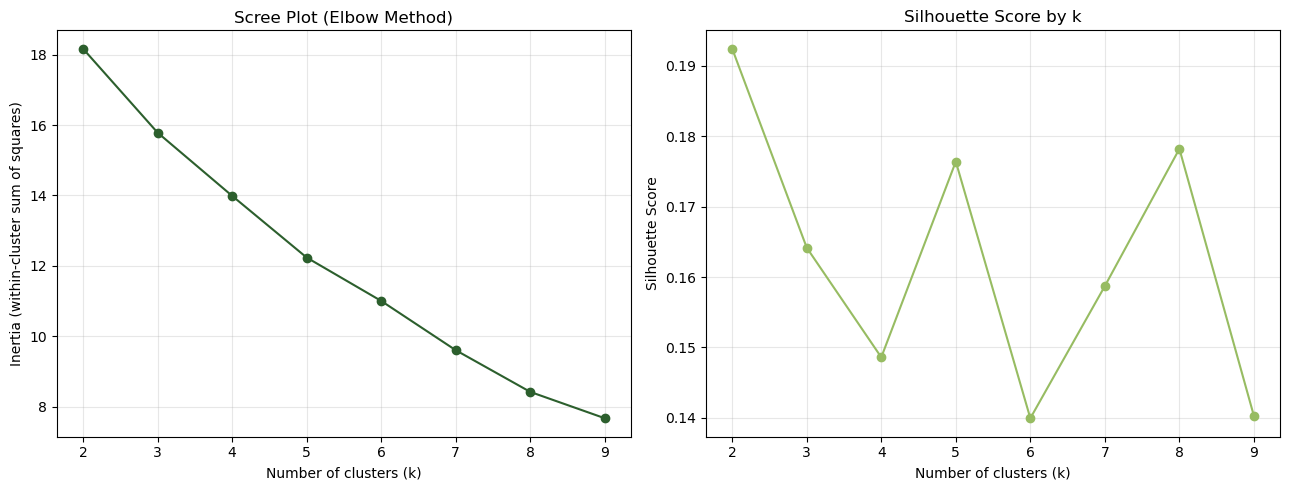

k=2: inertia=18.17, silhouette=0.192
k=3: inertia=15.78, silhouette=0.164
k=4: inertia=13.99, silhouette=0.149
k=5: inertia=12.24, silhouette=0.176
k=6: inertia=11.00, silhouette=0.140
k=7: inertia=9.60, silhouette=0.159
k=8: inertia=8.42, silhouette=0.178
k=9: inertia=7.67, silhouette=0.140


In [74]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_range = range(2, 10)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xn_final)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Xn_final, km.labels_))

# Scree plot (elbow method) — look for the "bend"
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(list(k_range), inertias, marker='o', color='#2C5F2D')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('Scree Plot (Elbow Method)')
axes[0].grid(alpha=0.3)

axes[1].plot(list(k_range), silhouettes, marker='o', color='#97BC62')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score by k')
axes[1].grid(alpha=0.3)

plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/kmeans_scree_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

for k, inertia, sil in zip(k_range, inertias, silhouettes):
    print(f"k={k}: inertia={inertia:.2f}, silhouette={sil:.3f}")

In [ ]:
# --- Independent literature validation --------------------------------------
# Compare the Monte Carlo top-5 / bottom-5 with what three external sources say.
# NOTE: fill LITERATURE_CLASSIFICATION yourself from the papers/reports cited in the
# report (MDPI Sustainability 2025; Springer Discover Sustainability 2025; EEA/Eurostat 2025).
# Allowed labels: "Top performer", "Strong performer", "Bottom performer",
# "Fragile/overstated", or "TODO" (not yet checked). Add a source note per country.
LITERATURE_CLASSIFICATION = {
    # "SI": "TODO",   # source: ...
}
validation_df = sensitivity_moderate_df.copy()

top5 = validation_df.nsmallest(5, "avg_rank_moderate")["country"].tolist()
bottom5 = validation_df.nlargest(5, "avg_rank_moderate")["country"].tolist()
print("Monte Carlo top 5 (most robust performers):", top5)
print("Monte Carlo bottom 5 (weakest performers):", bottom5)

if not any(v != "TODO" for v in LITERATURE_CLASSIFICATION.values()):
    print("\nLITERATURE_CLASSIFICATION is empty: add the classifications from the cited sources to compute agreement.")
else:
    top5_confirmed = [c for c in top5 if LITERATURE_CLASSIFICATION.get(c) in ("Top performer", "Strong performer")]
    bottom5_confirmed = [c for c in bottom5 if LITERATURE_CLASSIFICATION.get(c) == "Bottom performer"]
    print(f"\nTop 5 confirmed by literature: {len(top5_confirmed)}/5 -> {top5_confirmed}")
    print(f"Bottom 5 confirmed by literature: {len(bottom5_confirmed)}/5 -> {bottom5_confirmed}")
    n = len(top5_confirmed) + len(bottom5_confirmed)
    print(f"Overall agreement: {n}/10 = {n/10:.0%}")
    fragile = [c for c in ["LU", "FI"] if LITERATURE_CLASSIFICATION.get(c) == "Fragile/overstated"]
    print(f"Countries described as overstated/fragile in the literature: {fragile}")


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel 1: single-method rank vs Monte Carlo average rank
countries_plot = ["LU", "FI", "SK", "CZ", "SI"]
entropy_rank = [results_df.set_index("country").loc[c, "topsis_rank_entropy"] for c in countries_plot]
robust_rank = [sensitivity_moderate_df.set_index("country").loc[c, "avg_rank_moderate"] for c in countries_plot]

x = np.arange(len(countries_plot))
width = 0.35
axes[0].bar(x - width/2, entropy_rank, width, label="Single-method rank (entropy)", color="#97BC62")
axes[0].bar(x + width/2, robust_rank, width, label="Monte Carlo avg rank (5,000 scenarios)", color="#2C5F2D")
axes[0].set_xticks(x)
axes[0].set_xticklabels(countries_plot)
axes[0].set_ylabel("Rank (lower = better)")
axes[0].set_title("Single-method rank vs. Monte Carlo robustness")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3, axis='y')

# Panel 2: EEA (Nov 2025) reports decreases of MORE THAN 50% in the circular material use rate
# 2010-2024 for Finland, Romania and Luxembourg. Exact values are not used here: bars are drawn at
# the -50% threshold and are only a visual marker of ">50% decline", not measured data.
real_cmur_change = {"LU": -50, "FI": -50, "RO": -50}
eea_countries = list(real_cmur_change.keys())
eea_values = list(real_cmur_change.values())

axes[1].bar(eea_countries, eea_values, color="#C0392B")
axes[1].set_ylabel("CMUR change 2010-2024 (threshold marker, %)")
axes[1].set_title("Context: EEA-reported CMUR decline\n(bars = ">50%" threshold, not exact values)")
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].grid(alpha=0.3, axis='y')
axes[1].text(0.5, -60, "EEA: 'significant decreases (>50%) in CMUR\nwere seen in Finland, Romania and Luxembourg'",
             ha='center', fontsize=8, style='italic', transform=axes[1].transData)

plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/literature_validation_chart.png", dpi=150, bbox_inches="tight")
plt.show()

print("Interpretation: the Monte Carlo analysis shows Luxembourg's and Finland's high single-method")
print("ranks are sensitive to the weights chosen. Separately, the EEA reports >50% declines in their")
print("circular material use rate (2010-2024). The two observations are consistent, but the second")
print("does not by itself prove the first.")


In [77]:
print(df_eu.shape)
print(INDICATOR_SPEC.keys() if 'INDICATOR_SPEC' in dir() else "INDICATOR_SPEC missing")

(62175, 17)
dict_keys(['estat_cei_cie011', 'estat_cei_cie012', 'estat_cei_cie020', 'estat_cei_pc020', 'estat_cei_pc030', 'estat_cei_pc031', 'estat_cei_pc032', 'estat_cei_pc034', 'estat_cei_pc035', 'estat_cei_pc040', 'estat_cei_pc050', 'estat_cei_srm030', 'estat_cei_wm010', 'estat_cei_wm011', 'estat_cei_wm020', 'estat_cei_wm060'])


In [78]:
import pandas as pd
import numpy as np

def build_indicator_year_panel(df_eu, spec, years):
    panels = []
    for dataset_code, (filters, name, direction) in spec.items():
        g = df_eu[df_eu.dataset_code == dataset_code].copy()
        for col, val in filters.items():
            g = g[g[col] == val]
        g = g[g.year.isin(years)]
        s = g.groupby(["geo", "year"])["value"].mean().rename(name)
        panels.append(s)
    panel = pd.concat(panels, axis=1)
    return panel

ALL_YEARS = range(2010, 2025)
panel = build_indicator_year_panel(df_eu, INDICATOR_SPEC, ALL_YEARS)
panel = panel.reset_index()
panel = panel[panel.geo.isin(EU27)]

print("Panel shape:", panel.shape)
panel.head()

Panel shape: (405, 18)


,geo,year,employment_ce_pct,value_added_ce_pct_gdp,recycling_patents_per_mhab,raw_material_consumption_pc,resource_productivity,municipal_waste_generation_pc,material_footprint_intensity,household_waste_generation_pc,packaging_waste_generation_pc,packaging_waste_by_material_pc,plastic_packaging_waste_pc,circular_material_use_rate,municipal_waste_recovery_rate,packaging_waste_recycling_rate,packaging_recycling_progress_to_target,waste_recovery_rate_pct
0,AT,2010,1.5,2.1,1.23,24.076,1.7039,562.0,54.0,5596.0,NaN,147.17,31.63,6.8,60.0,59.4,66.6,79.9
1,AT,2011,1.5,2.1,1.92,25.966,1.6786,573.0,NaN,NaN,NaN,146.82,31.48,6.9,NaN,56.7,65.8,81.5
2,AT,2012,1.5,2.1,1.36,25.133,1.8399,579.0,48.0,5699.0,NaN,148.70,32.24,7.9,65.0,57.7,65.9,80.0
3,AT,2013,1.5,2.1,1.23,23.843,1.9018,578.0,NaN,NaN,NaN,149.97,34.05,9.1,NaN,57.7,66.6,79.0
4,AT,2014,1.5,2.2,0.94,24.082,1.8915,565.0,51.0,6537.0,NaN,152.52,34.16,9.9,62.0,56.3,66.6,79.6


In [79]:
FEATURE_COLS_FULL = list(indicator_names)  # same 16 indicators as before

panel_clean = panel.dropna(subset=FEATURE_COLS_FULL, thresh=int(len(FEATURE_COLS_FULL)*0.7)).copy()
print(f"Rows after dropping sparse rows: {len(panel_clean)} (from {len(panel)})")

from sklearn.impute import KNNImputer
imputer = KNNImputer(n_neighbors=5)
X_panel = imputer.fit_transform(panel_clean[FEATURE_COLS_FULL])

print("X_panel shape:", X_panel.shape)

Rows after dropping sparse rows: 370 (from 405)
X_panel shape: (370, 16)


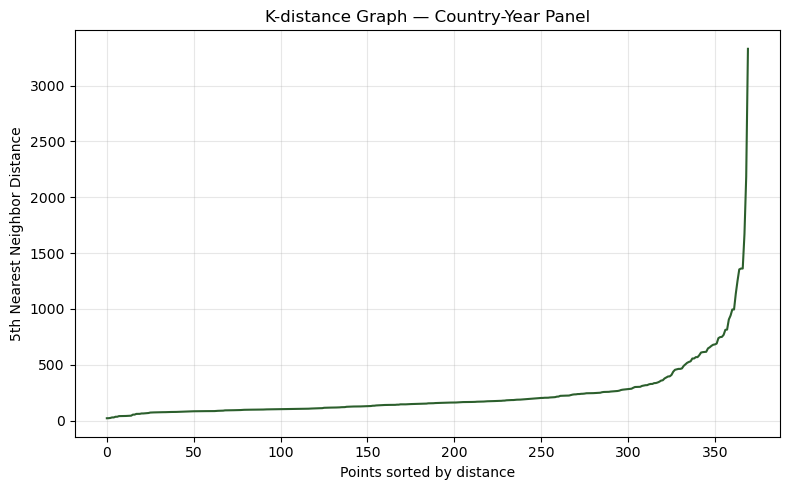

Distance range: 20.839 to 3329.031


In [80]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import os

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_panel)
distances, indices = neighbors_fit.kneighbors(X_panel)
distances = np.sort(distances[:, 4])

plt.figure(figsize=(8, 5))
plt.plot(distances, color='#2C5F2D')
plt.xlabel('Points sorted by distance')
plt.ylabel('5th Nearest Neighbor Distance')
plt.title('K-distance Graph — Country-Year Panel')
plt.grid(alpha=0.3)
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/dbscan_kdistance_panel.png", dpi=150, bbox_inches="tight")
plt.show()
print("Distance range:", distances.min().round(3), "to", distances.max().round(3))

In [81]:
#NORMALISATION


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_panel_scaled = scaler.fit_transform(X_panel)

print("Before scaling - example ranges:")
print(f"  Min: {X_panel.min(axis=0)[:3].round(2)}")
print(f"  Max: {X_panel.max(axis=0)[:3].round(2)}")
print("\nAfter scaling - should be roughly mean=0, std=1 for all columns:")
print(f"  Mean: {X_panel_scaled.mean(axis=0)[:3].round(3)}")
print(f"  Std: {X_panel_scaled.std(axis=0)[:3].round(3)}")

Before scaling - example ranges:
  Min: [1.1 0.5 0. ]
  Max: [ 7.9   7.9  11.66]

After scaling - should be roughly mean=0, std=1 for all columns:
  Mean: [0. 0. 0.]
  Std: [1. 1. 1.]


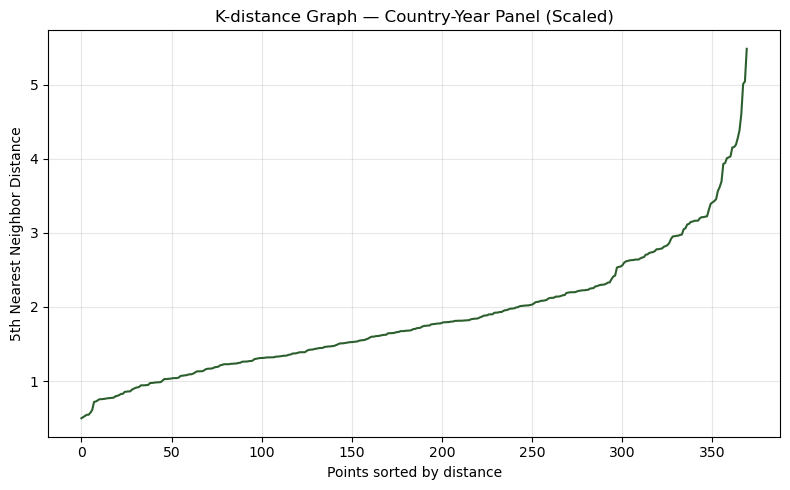

Distance range: 0.499 to 5.482


In [82]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_panel_scaled)
distances, indices = neighbors_fit.kneighbors(X_panel_scaled)
distances = np.sort(distances[:, 4])

plt.figure(figsize=(8, 5))
plt.plot(distances, color='#2C5F2D')
plt.xlabel('Points sorted by distance')
plt.ylabel('5th Nearest Neighbor Distance')
plt.title('K-distance Graph — Country-Year Panel (Scaled)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/dbscan_kdistance_panel_scaled.png", dpi=150, bbox_inches="tight")
plt.show()
print("Distance range:", distances.min().round(3), "to", distances.max().round(3))

In [83]:
from sklearn.cluster import DBSCAN

for eps_test in [1.5, 1.8, 2.0, 2.2, 2.5, 2.8, 3.0]:
    for min_samp in [5, 8, 10, 15]:
        db_test = DBSCAN(eps=eps_test, min_samples=min_samp).fit(X_panel_scaled)
        n_clusters = len(set(db_test.labels_)) - (1 if -1 in db_test.labels_ else 0)
        n_noise = list(db_test.labels_).count(-1)
        print(f"eps={eps_test}, min_samples={min_samp}: {n_clusters} clusters, {n_noise} noise points")

eps=1.5, min_samples=5: 17 clusters, 184 noise points
eps=1.5, min_samples=8: 10 clusters, 254 noise points
eps=1.5, min_samples=10: 5 clusters, 306 noise points
eps=1.5, min_samples=15: 1 clusters, 355 noise points
eps=1.8, min_samples=5: 17 clusters, 111 noise points
eps=1.8, min_samples=8: 10 clusters, 190 noise points
eps=1.8, min_samples=10: 9 clusters, 220 noise points
eps=1.8, min_samples=15: 1 clusters, 344 noise points
eps=2.0, min_samples=5: 10 clusters, 78 noise points
eps=2.0, min_samples=8: 9 clusters, 114 noise points
eps=2.0, min_samples=10: 5 clusters, 176 noise points
eps=2.0, min_samples=15: 4 clusters, 259 noise points
eps=2.2, min_samples=5: 8 clusters, 57 noise points
eps=2.2, min_samples=8: 5 clusters, 91 noise points
eps=2.2, min_samples=10: 2 clusters, 142 noise points
eps=2.2, min_samples=15: 1 clusters, 195 noise points
eps=2.5, min_samples=5: 4 clusters, 45 noise points
eps=2.5, min_samples=8: 5 clusters, 62 noise points
eps=2.5, min_samples=10: 3 clusters, 9

In [84]:
eps_value = 2.5
min_samples_value = 5

dbscan_panel = DBSCAN(eps=eps_value, min_samples=min_samples_value)
db_labels_panel = dbscan_panel.fit_predict(X_panel_scaled)

panel_result_df = panel_clean[["geo", "year"]].copy()
panel_result_df["dbscan_cluster"] = db_labels_panel

n_clusters_found = len(set(db_labels_panel)) - (1 if -1 in db_labels_panel else 0)
n_noise = list(db_labels_panel).count(-1)
print(f"DBSCAN (eps={eps_value}, min_samples={min_samples_value}): {n_clusters_found} clusters, {n_noise} noise points out of {len(db_labels_panel)} ({n_noise/len(db_labels_panel):.1%})")

# Aggregate to country level: which countries have the most anomalous years?
noise_by_country = panel_result_df[panel_result_df["dbscan_cluster"] == -1].groupby("geo").size().sort_values(ascending=False)
print("\nCountries with most anomalous country-year observations flagged:")
print(noise_by_country)

# Also show cluster sizes for context
print("\nCluster sizes:")
print(panel_result_df["dbscan_cluster"].value_counts().sort_index())

DBSCAN (eps=2.5, min_samples=5): 4 clusters, 45 noise points out of 370 (12.2%)

Countries with most anomalous country-year observations flagged:
geo
MT    14
LU    13
EE     8
IE     3
DK     2
SE     2
CY     1
FI     1
SI     1
dtype: int64

Cluster sizes:
dbscan_cluster
-1     45
 0    298
 1      6
 2     12
 3      9
Name: count, dtype: int64


  plt.scatter(X_pca[mask, 0], X_pca[mask, 1],


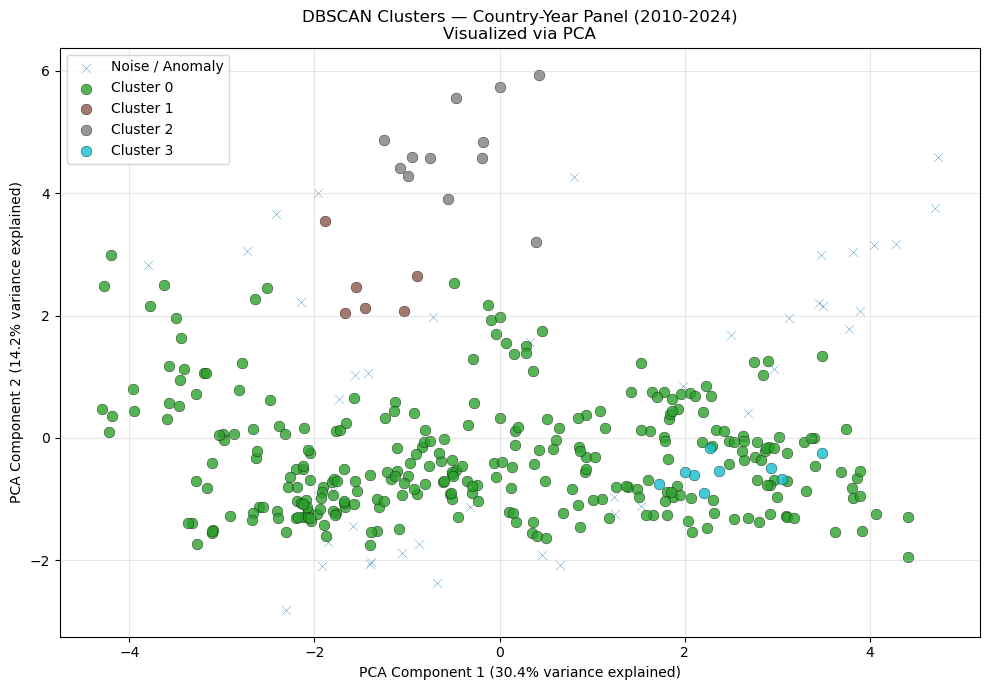

Note: PCA components explain 44.5% of total variance
(some information is lost when reducing 16 dimensions to 2 for visualization)


In [85]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce 16 dimensions down to 2 for visualization only (doesn't affect the actual clustering)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_panel_scaled)

plt.figure(figsize=(10, 7))

# Plot each cluster in a different color
unique_labels = sorted(set(db_labels_panel))
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

for label, color in zip(unique_labels, colors):
    mask = db_labels_panel == label
    label_name = "Noise / Anomaly" if label == -1 else f"Cluster {label}"
    marker = "x" if label == -1 else "o"
    size = 40 if label == -1 else 60
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=[color], label=label_name, marker=marker, s=size,
                edgecolors='black', linewidths=0.3, alpha=0.8)

plt.xlabel(f"PCA Component 1 ({pca.explained_variance_ratio_[0]:.1%} variance explained)")
plt.ylabel(f"PCA Component 2 ({pca.explained_variance_ratio_[1]:.1%} variance explained)")
plt.title("DBSCAN Clusters — Country-Year Panel (2010-2024)\nVisualized via PCA")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/dbscan_pca_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Note: PCA components explain {pca.explained_variance_ratio_.sum():.1%} of total variance")
print("(some information is lost when reducing 16 dimensions to 2 for visualization)")

In [86]:
for cluster_id in [1, 2, 3]:
    members = panel_result_df[panel_result_df["dbscan_cluster"] == cluster_id]
    print(f"\nCluster {cluster_id} members ({len(members)} country-years):")
    print(members.sort_values(["geo", "year"]).to_string(index=False))


Cluster 1 members (6 country-years):
geo  year  dbscan_cluster
 EE  2015               1
 EE  2017               1
 EE  2018               1
 EE  2019               1
 EE  2020               1
 EE  2021               1

Cluster 2 members (12 country-years):
geo  year  dbscan_cluster
 FI  2010               2
 FI  2011               2
 FI  2012               2
 FI  2013               2
 FI  2014               2
 FI  2015               2
 FI  2016               2
 FI  2017               2
 FI  2018               2
 FI  2019               2
 FI  2020               2
 FI  2022               2

Cluster 3 members (9 country-years):
geo  year  dbscan_cluster
 IE  2014               3
 IE  2016               3
 IE  2017               3
 IE  2018               3
 IE  2019               3
 IE  2020               3
 IE  2021               3
 IE  2022               3
 IE  2023               3


In [91]:
cluster0_mean = X_panel[db_labels_panel == 0].mean(axis=0)
cluster0_std = X_panel[db_labels_panel == 0].std(axis=0)

noise_mask = db_labels_panel == -1
noise_indices = panel_clean[noise_mask].index

noise_profile = pd.DataFrame(
    X_panel[noise_mask],
    columns=FEATURE_COLS_FULL,
    index=panel_clean.loc[noise_indices, ["geo", "year"]].apply(lambda r: f"{r['geo']}_{r['year']}", axis=1)
)

# FIXED: no .values — cluster0_mean/std are already arrays
noise_zscores = (noise_profile - cluster0_mean) / cluster0_std
noise_zscores.to_csv("data/dbscan_noise_zscores.csv")

top_driver_per_point = noise_zscores.abs().idxmax(axis=1)
top_driver_value = noise_zscores.abs().max(axis=1)

noise_summary = pd.DataFrame({
    "top_deviating_indicator": top_driver_per_point,
    "z_score_magnitude": top_driver_value.round(2)
}).sort_values("z_score_magnitude", ascending=False)

print(noise_summary.to_string())

                        top_deviating_indicator  z_score_magnitude
LU_2014              recycling_patents_per_mhab              19.51
IE_2010                  value_added_ce_pct_gdp              17.72
IE_2011                  value_added_ce_pct_gdp              16.88
IE_2012                  value_added_ce_pct_gdp              16.59
LU_2017              recycling_patents_per_mhab              16.55
LU_2020              recycling_patents_per_mhab              11.14
LU_2013              recycling_patents_per_mhab               9.82
FI_2021              recycling_patents_per_mhab               9.23
EE_2010            material_footprint_intensity               8.77
LU_2016              recycling_patents_per_mhab               8.17
EE_2014            material_footprint_intensity               8.06
EE_2012            material_footprint_intensity               7.65
LU_2012              recycling_patents_per_mhab               7.62
EE_2016            material_footprint_intensity               

In [93]:
# Add country back in for grouping
noise_zscores_with_country = noise_zscores.copy()
noise_zscores_with_country["geo"] = [idx.split("_")[0] for idx in noise_zscores.index]

# Average absolute z-score per indicator, per country — shows each flagged country's "signature"
country_driver_profile = noise_zscores_with_country.groupby("geo")[FEATURE_COLS_FULL].apply(lambda x: x.abs().mean())

print("Average deviation profile for each flagged country (top 5 indicators shown per country):\n")
for country in country_driver_profile.index:
    top5 = country_driver_profile.loc[country].sort_values(ascending=False).head(5)
    print(f"{country}:")
    print(top5.round(2).to_string())
    print()

Average deviation profile for each flagged country (top 5 indicators shown per country):

CY:
raw_material_consumption_pc       2.96
waste_recovery_rate_pct           1.89
municipal_waste_generation_pc     1.81
packaging_waste_generation_pc     1.72
packaging_waste_recycling_rate    1.58

DK:
recycling_patents_per_mhab       5.52
packaging_waste_generation_pc    3.51
municipal_waste_generation_pc    2.20
waste_recovery_rate_pct          1.72
raw_material_consumption_pc      1.65

EE:
material_footprint_intensity     5.65
employment_ce_pct                2.29
household_waste_generation_pc    2.19
plastic_packaging_waste_pc       1.80
municipal_waste_recovery_rate    1.77

FI:
recycling_patents_per_mhab       9.23
raw_material_consumption_pc      5.54
resource_productivity            1.22
municipal_waste_generation_pc    1.16
household_waste_generation_pc    1.15

IE:
value_added_ce_pct_gdp            17.07
plastic_packaging_waste_pc         1.30
packaging_waste_by_material_pc     1.10
m

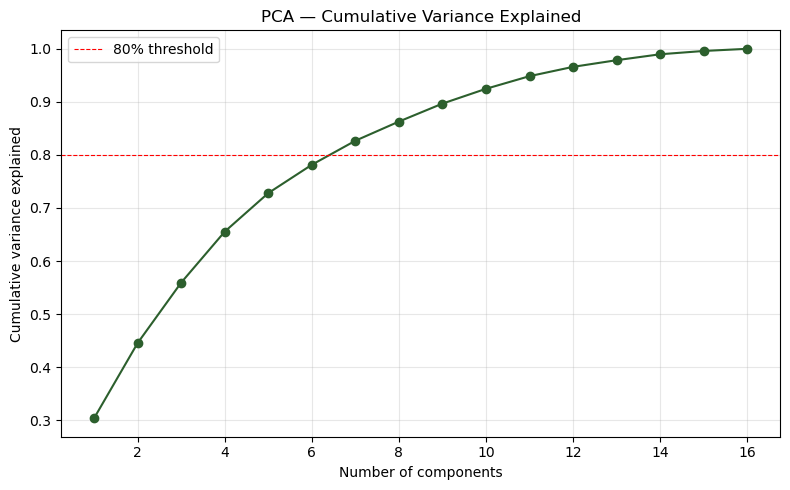

PC1: 30.4% (cumulative: 30.4%)
PC2: 14.2% (cumulative: 44.5%)
PC3: 11.4% (cumulative: 55.9%)
PC4: 9.6% (cumulative: 65.5%)
PC5: 7.3% (cumulative: 72.8%)
PC6: 5.3% (cumulative: 78.1%)
PC7: 4.5% (cumulative: 82.7%)
PC8: 3.6% (cumulative: 86.3%)
PC9: 3.4% (cumulative: 89.7%)
PC10: 2.8% (cumulative: 92.5%)
PC11: 2.4% (cumulative: 94.8%)
PC12: 1.8% (cumulative: 96.6%)
PC13: 1.3% (cumulative: 97.9%)
PC14: 1.1% (cumulative: 99.0%)
PC15: 0.6% (cumulative: 99.6%)
PC16: 0.4% (cumulative: 100.0%)


In [95]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Full PCA (all components) to see variance explained by each
pca_full = PCA(n_components=len(FEATURE_COLS_FULL), random_state=42)
pca_full.fit(X_panel_scaled)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(pca_full.explained_variance_ratio_)+1),
          np.cumsum(pca_full.explained_variance_ratio_), marker='o', color='#2C5F2D')
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance explained")
plt.title("PCA — Cumulative Variance Explained")
plt.grid(alpha=0.3)
plt.axhline(0.8, color='red', linestyle='--', linewidth=0.8, label='80% threshold')
plt.legend()
plt.tight_layout()
plt.savefig("outputs/pca_cumulative_variance.png", dpi=150, bbox_inches="tight")
plt.show()

for i, (var, cum) in enumerate(zip(pca_full.explained_variance_ratio_, np.cumsum(pca_full.explained_variance_ratio_))):
    print(f"PC{i+1}: {var:.1%} (cumulative: {cum:.1%})")

In [96]:
# What do PC1 and PC2 actually represent? (loadings — which indicators drive each component)
loadings = pd.DataFrame(
    pca_full.components_[:2].T,
    columns=["PC1", "PC2"],
    index=FEATURE_COLS_FULL
).sort_values("PC1", ascending=False)

print("PC1 loadings (top drivers):")
print(loadings["PC1"].round(3))
print("\nPC2 loadings (top drivers):")
print(loadings.sort_values("PC2", ascending=False)["PC2"].round(3))

PC1 loadings (top drivers):
packaging_waste_by_material_pc            0.377
packaging_waste_recycling_rate            0.374
resource_productivity                     0.347
municipal_waste_recovery_rate             0.317
circular_material_use_rate                0.295
plastic_packaging_waste_pc                0.288
packaging_recycling_progress_to_target    0.275
municipal_waste_generation_pc             0.264
recycling_patents_per_mhab                0.210
value_added_ce_pct_gdp                    0.104
raw_material_consumption_pc              -0.021
household_waste_generation_pc            -0.028
waste_recovery_rate_pct                  -0.054
packaging_waste_generation_pc            -0.074
material_footprint_intensity             -0.212
employment_ce_pct                        -0.267
Name: PC1, dtype: float64

PC2 loadings (top drivers):
household_waste_generation_pc             0.568
raw_material_consumption_pc               0.566
recycling_patents_per_mhab                0.378
mater

In [ ]:
# PCA-based outlier detection: Mahalanobis-style distance in PCA space
# (points far from the center in PCA space = statistical outliers, independent of DBSCAN's density logic)
X_pca_2d = PCA(n_components=2, random_state=42).fit_transform(X_panel_scaled)

pca_center = X_pca_2d.mean(axis=0)
pca_distances = np.sqrt(((X_pca_2d - pca_center) ** 2).sum(axis=1))

# Flag top 12% as PCA outliers (matching DBSCAN's ~12% noise rate, for fair comparison)
threshold = np.percentile(pca_distances, 88)
pca_outlier_flag = pca_distances > threshold

comparison_df = panel_clean[["geo", "year"]].copy()
comparison_df["dbscan_noise"] = (db_labels_panel == -1)
comparison_df["pca_outlier"] = pca_outlier_flag
comparison_df["pca_distance"] = pca_distances.round(2)

# Agreement rate: how often do DBSCAN and PCA agree on what's an outlier?
agreement = (comparison_df["dbscan_noise"] == comparison_df["pca_outlier"]).mean()
both_flagged = ((comparison_df["dbscan_noise"]) & (comparison_df["pca_outlier"])).sum()

print(f"Overall agreement rate (both flag same way): {agreement:.1%}")
# Chance-corrected agreement: both methods flag ~12%, so ~79% agreement is expected by chance alone
p_d, p_p = comparison_df["dbscan_noise"].mean(), comparison_df["pca_outlier"].mean()
p_chance = p_d * p_p + (1 - p_d) * (1 - p_p)
kappa = (agreement - p_chance) / (1 - p_chance)
print(f"Agreement expected by chance: {p_chance:.1%} | Cohen's kappa: {kappa:.2f}")
print(f"Expected overlap by chance: {comparison_df['dbscan_noise'].sum() * p_p:.1f} points (observed: {both_flagged})")
print(f"Points flagged as outlier by BOTH methods: {both_flagged}")
print(f"\nCountries flagged by BOTH DBSCAN and PCA distance:")
both_df = comparison_df[(comparison_df["dbscan_noise"]) & (comparison_df["pca_outlier"])]
print(both_df.groupby("geo").size().sort_values(ascending=False))

In [99]:
from scipy.stats import spearmanr

# Build country-level PCA (using the same Xn_final matrix as the main ranking, for direct comparability)
pca_ranking = PCA(n_components=1, random_state=42)
pc1_scores = pca_ranking.fit_transform(Xn_final).flatten()

# Check sign: PC1's direction is arbitrary, so orient it to match "higher = better" if needed
pc1_series = pd.Series(pc1_scores, index=countries)

pca_adjusted_df = results_df[["country", "topsis_rank_entropy", "topsis_rank_critic"]].copy()
pca_adjusted_df["pc1_score"] = pca_adjusted_df["country"].map(pc1_series)
pca_adjusted_df["pc1_rank"] = pca_adjusted_df["pc1_score"].rank(ascending=False)

rho_entropy, p1 = spearmanr(pca_adjusted_df["topsis_rank_entropy"], pca_adjusted_df["pc1_rank"])
rho_critic, p2 = spearmanr(pca_adjusted_df["topsis_rank_critic"], pca_adjusted_df["pc1_rank"])

print(f"PC1 rank vs TOPSIS (entropy) rank: Spearman rho = {rho_entropy:.3f} (p={p1:.4f})")
print(f"PC1 rank vs TOPSIS (CRITIC) rank:  Spearman rho = {rho_critic:.3f} (p={p2:.4f})")
print(f"\nPC1 explains {pca_ranking.explained_variance_ratio_[0]:.1%} of total variance on its own")

pca_adjusted_df.sort_values("pc1_rank").to_csv("data/pca_adjusted_ranking.csv", index=False)
pca_adjusted_df.sort_values("pc1_rank")

PC1 rank vs TOPSIS (entropy) rank: Spearman rho = -0.768 (p=0.0000)
PC1 rank vs TOPSIS (CRITIC) rank:  Spearman rho = -0.209 (p=0.2960)

PC1 explains 32.6% of total variance on its own


,country,topsis_rank_entropy,topsis_rank_critic,pc1_score,pc1_rank
23,RO,27,27,0.988189,1.0
2,BG,26,22,0.793001,2.0
12,HR,11,1,0.749360,3.0
3,CY,23,18,0.606139,4.0
8,EL,24,19,0.555497,5.0
7,EE,18,17,0.433814,6.0
16,LT,15,9,0.390408,7.0
13,HU,21,16,0.350808,8.0
18,LV,14,5,0.319670,9.0
22,PT,25,24,0.281607,10.0


In [100]:
# Build a combined table: every point's cluster label + its 16 indicator values
profile_df = pd.DataFrame(X_panel, columns=FEATURE_COLS_FULL)
profile_df["dbscan_cluster"] = db_labels_panel
profile_df["geo"] = panel_clean["geo"].values
profile_df["year"] = panel_clean["year"].values

# Mean indicator profile per cluster (including noise as its own row)
cluster_means = profile_df.groupby("dbscan_cluster")[FEATURE_COLS_FULL].mean().round(2)
cluster_means.index = ["Noise (-1)" if i == -1 else f"Cluster {i}" for i in cluster_means.index]

print("Mean indicator values per cluster:\n")
print(cluster_means.T)  # transposed so indicators are rows, easy to scan

Mean indicator values per cluster:

                                        Noise (-1)  Cluster 0  Cluster 1  \
employment_ce_pct                             2.78       2.33       3.72   
value_added_ce_pct_gdp                        2.24       1.63       2.20   
recycling_patents_per_mhab                    2.16       0.63       0.12   
raw_material_consumption_pc                  21.08      16.17      28.39   
resource_productivity                         2.31       1.94       0.88   
municipal_waste_generation_pc               594.98     485.50     383.50   
material_footprint_intensity                143.60      98.26     464.27   
household_waste_generation_pc              8910.69    5210.69   13549.57   
packaging_waste_generation_pc               160.00     137.91     122.73   
packaging_waste_by_material_pc              168.05     134.21     161.36   
plastic_packaging_waste_pc                   36.50      27.41      43.27   
circular_material_use_rate                   10.75  

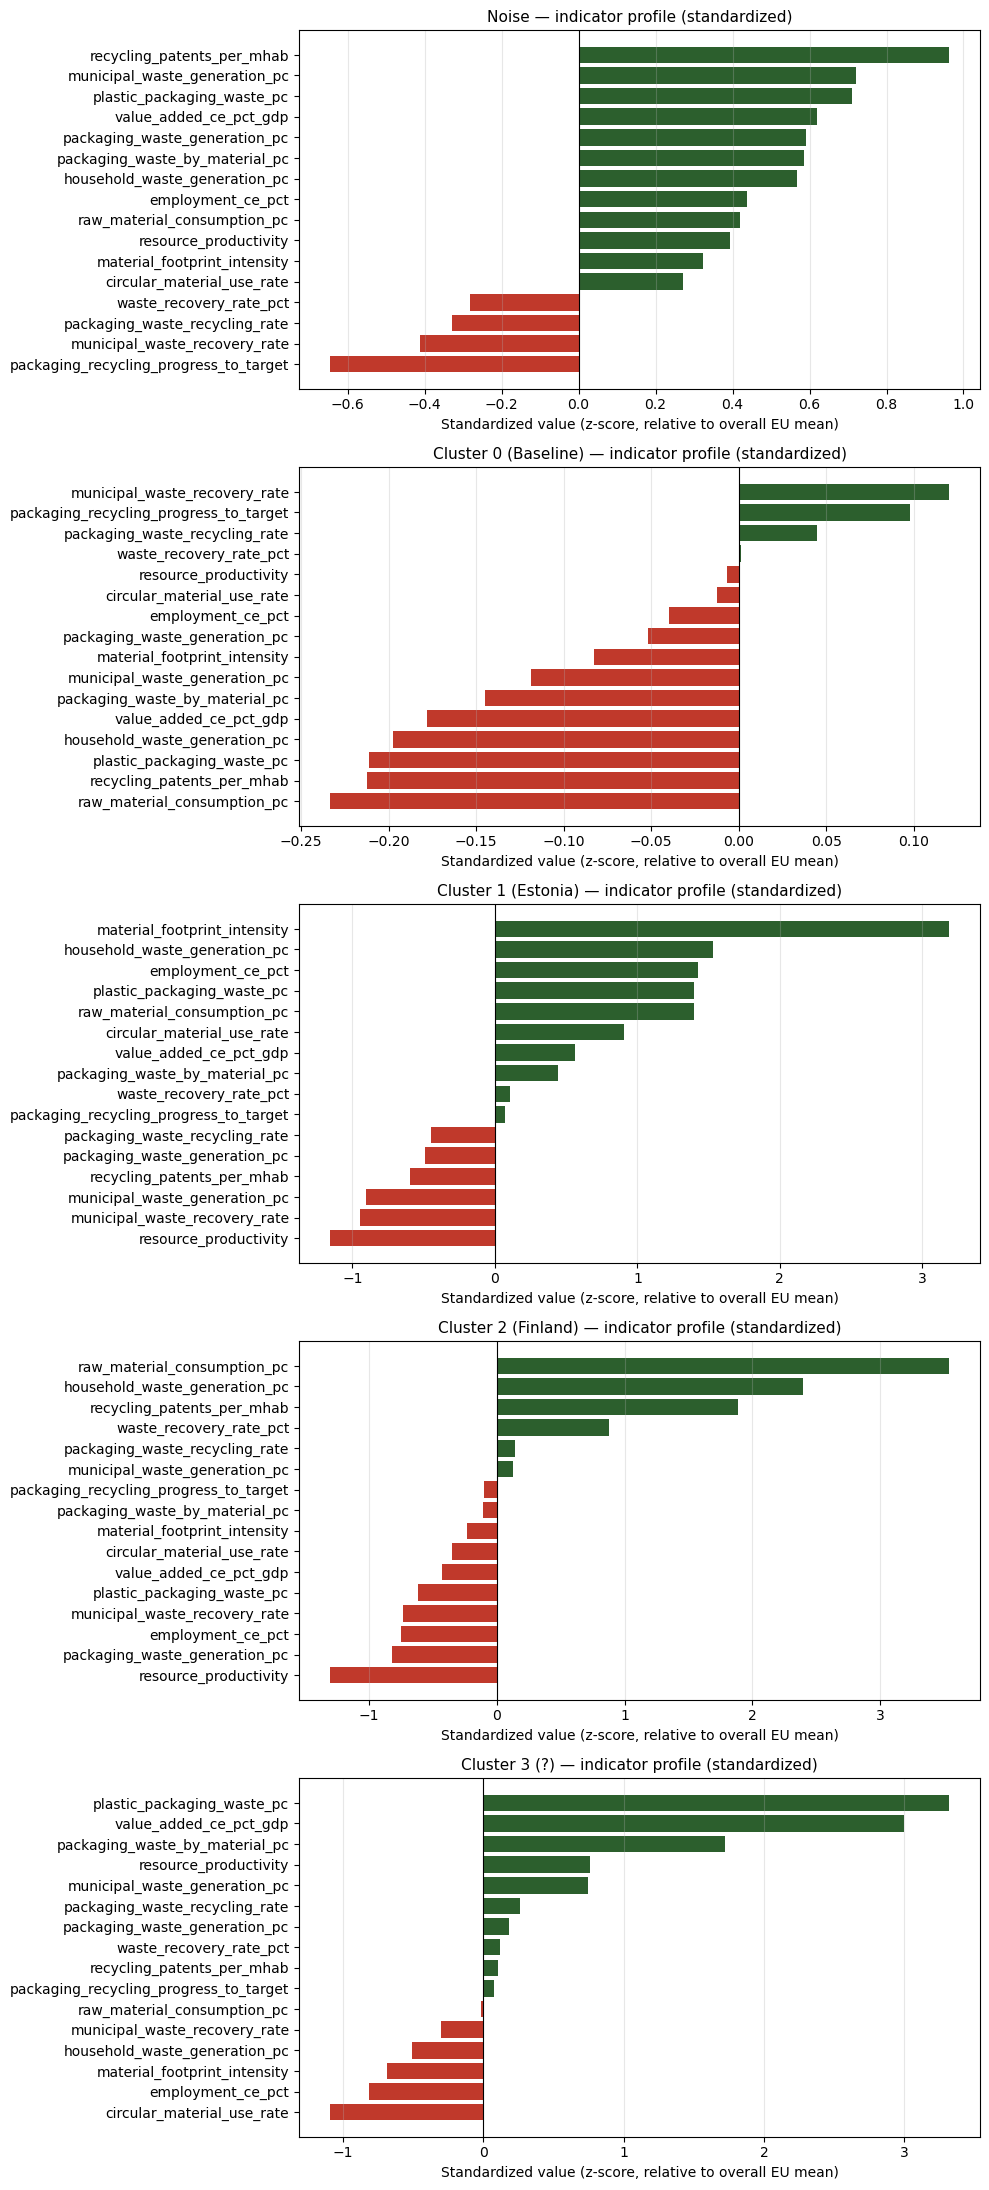

In [102]:
import matplotlib.pyplot as plt
import numpy as np

profile_scaled = pd.DataFrame(X_panel_scaled, columns=FEATURE_COLS_FULL, index=panel_clean.index)
profile_scaled["cluster"] = db_labels_panel

cluster_means_scaled = profile_scaled.groupby("cluster")[FEATURE_COLS_FULL].mean()
# Use the SCALED cluster means (fair comparison across indicators with different units)
cluster_means_scaled = profile_scaled.groupby("cluster")[FEATURE_COLS_FULL].mean()

cluster_labels = {-1: "Noise", 0: "Cluster 0 (Baseline)", 1: "Cluster 1 (Estonia)",
                   2: "Cluster 2 (Finland)", 3: "Cluster 3 (?)"}

fig, axes = plt.subplots(5, 1, figsize=(10, 22))

for ax, cluster_id in zip(axes, [-1, 0, 1, 2, 3]):
    values = cluster_means_scaled.loc[cluster_id].sort_values()
    colors = ['#C0392B' if v < 0 else '#2C5F2D' for v in values]
    ax.barh(values.index, values.values, color=colors)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f"{cluster_labels[cluster_id]} — indicator profile (standardized)", fontsize=11)
    ax.set_xlabel("Standardized value (z-score, relative to overall EU mean)")
    ax.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig("outputs/cluster_bar_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

In [103]:
import pandas as pd
import numpy as np

# Build a DataFrame with the panel features + cluster label
profile_all = pd.DataFrame(X_panel, columns=FEATURE_COLS_FULL, index=panel_clean.index)
profile_all["cluster"] = db_labels_panel

# Mean value of each indicator, per cluster (including -1 noise)
cluster_means = profile_all.groupby("cluster")[FEATURE_COLS_FULL].mean().round(2)
print(cluster_means.T)   # transposed: indicators as rows, clusters as columns — easy to scan

cluster                                      -1        0         1         2  \
employment_ce_pct                          2.78     2.33      3.72      1.66   
value_added_ce_pct_gdp                     2.24     1.63      2.20      1.43   
recycling_patents_per_mhab                 2.16     0.63      0.12      3.37   
raw_material_consumption_pc               21.08    16.17     28.39     44.47   
resource_productivity                      2.31     1.94      0.88      0.75   
municipal_waste_generation_pc            594.98   485.50    383.50    518.17   
material_footprint_intensity             143.60    98.26    464.27     81.58   
household_waste_generation_pc           8910.69  5210.69  13549.57  17722.25   
packaging_waste_generation_pc            160.00   137.91    122.73    111.50   
packaging_waste_by_material_pc           168.05   134.21    161.36    136.09   
plastic_packaging_waste_pc                36.50    27.41     43.27     23.46   
circular_material_use_rate              

In [105]:
# Variance of each indicator's cluster-mean across the 5 groups — high variance = strong differentiator
between_cluster_variance = cluster_means.var(axis=0).sort_values(ascending=False)
print("Indicators that most distinguish the 5 groups from each other:\n")
print(between_cluster_variance.round(3))

Indicators that most distinguish the 5 groups from each other:

household_waste_generation_pc             3.394114e+07
material_footprint_intensity              2.985406e+04
municipal_waste_generation_pc             7.890811e+03
packaging_waste_by_material_pc            1.217122e+03
packaging_waste_generation_pc             3.634630e+02
plastic_packaging_waste_pc                2.344020e+02
raw_material_consumption_pc               1.334750e+02
municipal_waste_recovery_rate             3.089900e+01
packaging_waste_recycling_rate            2.328200e+01
circular_material_use_rate                2.272800e+01
waste_recovery_rate_pct                   9.624000e+00
packaging_recycling_progress_to_target    9.603000e+00
recycling_patents_per_mhab                1.700000e+00
value_added_ce_pct_gdp                    1.105000e+00
employment_ce_pct                         7.690000e-01
resource_productivity                     7.270000e-01
dtype: float64


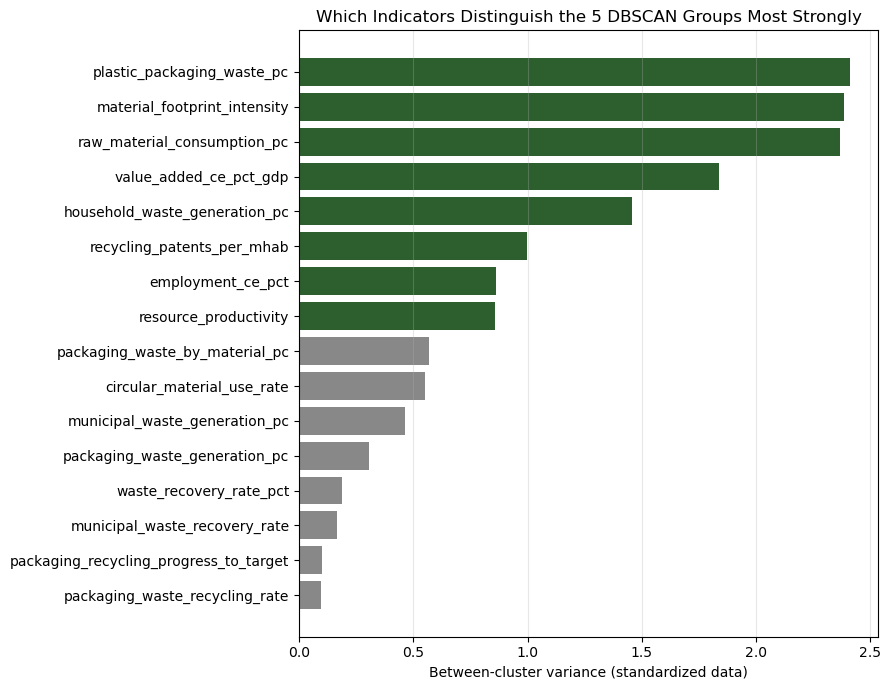

In [106]:
import matplotlib.pyplot as plt

# Use the SCALED version - the raw version overweights large-unit indicators
cluster_means_scaled = profile_scaled.groupby("cluster")[FEATURE_COLS_FULL].mean()
between_cluster_variance_scaled = cluster_means_scaled.var(axis=0).sort_values(ascending=True)  # ascending for barh so biggest ends up on top

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#2C5F2D' if v >= between_cluster_variance_scaled.median() else '#888888'
          for v in between_cluster_variance_scaled.values]

ax.barh(between_cluster_variance_scaled.index, between_cluster_variance_scaled.values, color=colors)
ax.set_xlabel("Between-cluster variance (standardized data)")
ax.set_title("Which Indicators Distinguish the 5 DBSCAN Groups Most Strongly")
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig("outputs/between_cluster_variance.png", dpi=150, bbox_inches="tight")
plt.show()

In [108]:
noise_mean = cluster_means.loc[-1]

comparison_vs_noise = pd.DataFrame({
    f"cluster_{c}_vs_noise": cluster_means.loc[c] - noise_mean
    for c in [0, 1, 2, 3]
}).round(2)

print(comparison_vs_noise)

# For each cluster, show its top 5 biggest differences from noise
for c in [0, 1, 2, 3]:
    print(f"\n--- Cluster {c} vs Noise: top 5 differences ---")
    print(comparison_vs_noise[f"cluster_{c}_vs_noise"].abs().sort_values(ascending=False).head(5))

                                        cluster_0_vs_noise  \
employment_ce_pct                                    -0.45   
value_added_ce_pct_gdp                               -0.61   
recycling_patents_per_mhab                           -1.53   
raw_material_consumption_pc                          -4.91   
resource_productivity                                -0.37   
municipal_waste_generation_pc                      -109.48   
material_footprint_intensity                        -45.34   
household_waste_generation_pc                     -3700.00   
packaging_waste_generation_pc                       -22.09   
packaging_waste_by_material_pc                      -33.84   
plastic_packaging_waste_pc                           -9.09   
circular_material_use_rate                           -1.82   
municipal_waste_recovery_rate                         7.23   
packaging_waste_recycling_rate                        5.88   
packaging_recycling_progress_to_target                7.30   
waste_re

In [110]:
sizes = profile_all["cluster"].value_counts().sort_index()
print("Group sizes:\n", sizes)

# Which countries make up each cluster (you already have this for 1,2,3 from cell 159 — add cluster 0 + noise)
for c in [0, -1]:
    members = panel_clean.loc[profile_all[profile_all["cluster"] == c].index, ["geo", "year"]]
    print(f"\nCluster {c} — top countries by frequency:")
    print(members["geo"].value_counts().head(10))

Group sizes:
 cluster
-1     45
 0    298
 1      6
 2     12
 3      9
Name: count, dtype: int64

Cluster 0 — top countries by frequency:
geo
AT    14
FR    14
RO    14
PT    14
NL    14
LV    14
LT    14
IT    14
BE    14
SK    14
Name: count, dtype: int64

Cluster -1 — top countries by frequency:
geo
MT    14
LU    13
EE     8
IE     3
DK     2
SE     2
CY     1
FI     1
SI     1
Name: count, dtype: int64


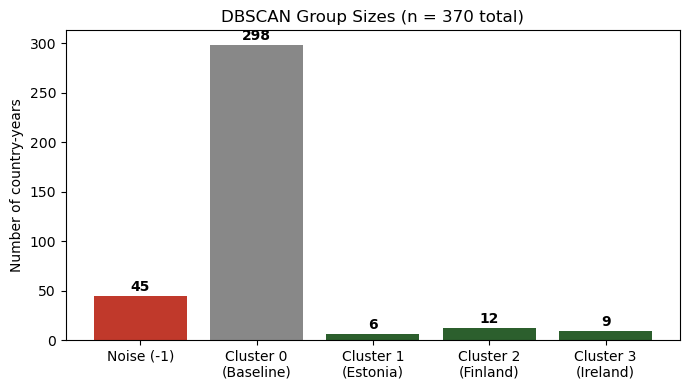

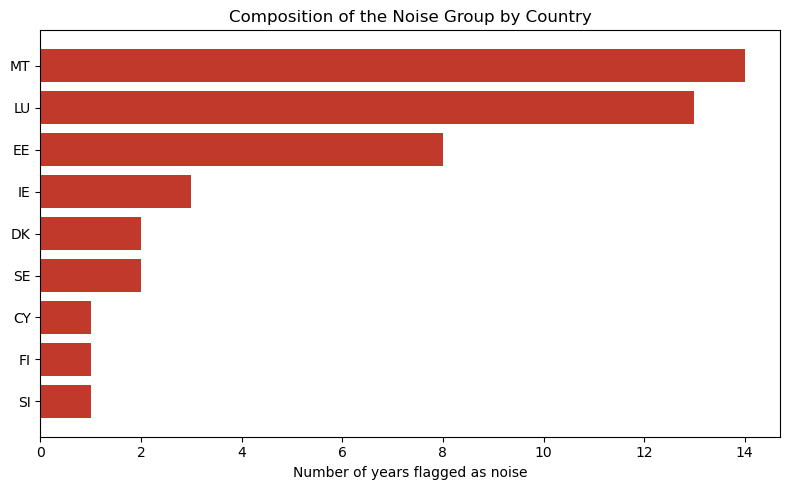

In [111]:
import matplotlib.pyplot as plt

# Chart 1: Group sizes
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Noise (-1)", "Cluster 0\n(Baseline)", "Cluster 1\n(Estonia)", "Cluster 2\n(Finland)", "Cluster 3\n(Ireland)"]
sizes_ordered = sizes.reindex([-1, 0, 1, 2, 3])
colors = ['#C0392B', '#888888', '#2C5F2D', '#2C5F2D', '#2C5F2D']
ax.bar(labels, sizes_ordered.values, color=colors)
ax.set_ylabel("Number of country-years")
ax.set_title("DBSCAN Group Sizes (n = 370 total)")
for i, v in enumerate(sizes_ordered.values):
    ax.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig("outputs/group_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 2: Which countries make up the noise group
noise_members = panel_clean.loc[profile_all[profile_all["cluster"] == -1].index, "geo"]
noise_counts = noise_members.value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(noise_counts.index[::-1], noise_counts.values[::-1], color='#C0392B')
ax.set_xlabel("Number of years flagged as noise")
ax.set_title("Composition of the Noise Group by Country")
plt.tight_layout()
plt.savefig("outputs/noise_composition.png", dpi=150, bbox_inches="tight")
plt.show()

In [112]:
profile_scaled = pd.DataFrame(X_panel_scaled, columns=FEATURE_COLS_FULL, index=panel_clean.index)
profile_scaled["cluster"] = db_labels_panel

cluster_means_scaled = profile_scaled.groupby("cluster")[FEATURE_COLS_FULL].mean()
between_cluster_variance_scaled = cluster_means_scaled.var(axis=0).sort_values(ascending=False)
print(between_cluster_variance_scaled.round(3))

plastic_packaging_waste_pc                2.412
material_footprint_intensity              2.382
raw_material_consumption_pc               2.369
value_added_ce_pct_gdp                    1.837
household_waste_generation_pc             1.456
recycling_patents_per_mhab                0.998
employment_ce_pct                         0.860
resource_productivity                     0.857
packaging_waste_by_material_pc            0.569
circular_material_use_rate                0.549
municipal_waste_generation_pc             0.464
packaging_waste_generation_pc             0.307
waste_recovery_rate_pct                   0.186
municipal_waste_recovery_rate             0.168
packaging_recycling_progress_to_target    0.100
packaging_waste_recycling_rate            0.094
dtype: float64


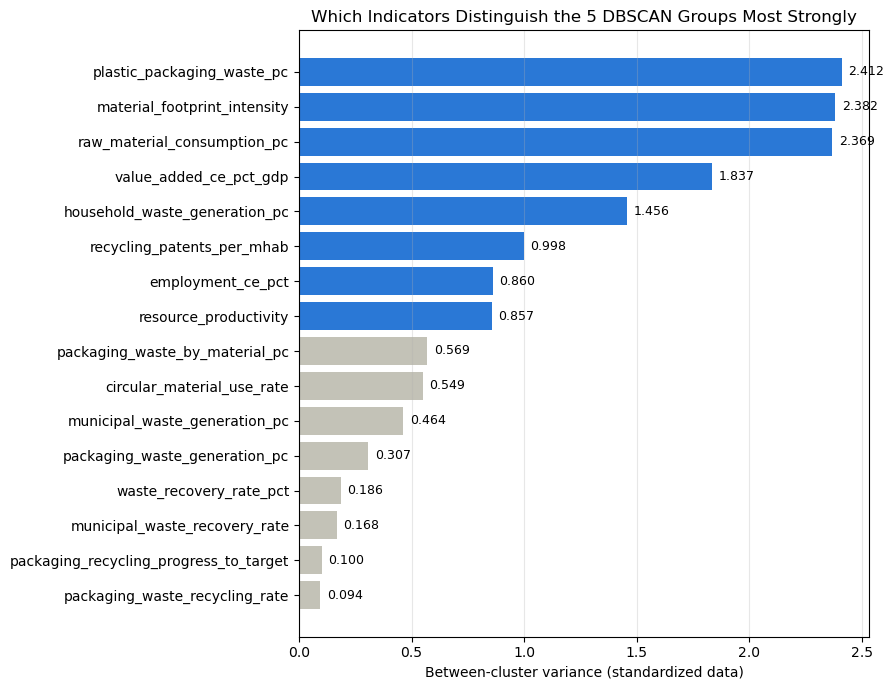

In [113]:
import matplotlib.pyplot as plt

# Use the SCALED version (fair comparison across indicators with different units)
profile_scaled = pd.DataFrame(X_panel_scaled, columns=FEATURE_COLS_FULL, index=panel_clean.index)
profile_scaled["cluster"] = db_labels_panel

cluster_means_scaled = profile_scaled.groupby("cluster")[FEATURE_COLS_FULL].mean()
between_cluster_variance_scaled = cluster_means_scaled.var(axis=0).sort_values(ascending=True)  # ascending so biggest bar ends up on top in barh

# Color bars above the median blue, below the median gray
median_val = between_cluster_variance_scaled.median()
colors = ['#2a78d6' if v >= median_val else '#c3c2b7' for v in between_cluster_variance_scaled.values]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(between_cluster_variance_scaled.index, between_cluster_variance_scaled.values, color=colors)
ax.set_xlabel("Between-cluster variance (standardized data)")
ax.set_title("Which Indicators Distinguish the 5 DBSCAN Groups Most Strongly")
ax.grid(alpha=0.3, axis='x')

for i, v in enumerate(between_cluster_variance_scaled.values):
    ax.text(v + 0.03, i, f"{v:.3f}", va='center', fontsize=9)

plt.tight_layout()
plt.savefig("outputs/between_cluster_variance.png", dpi=150, bbox_inches="tight")
plt.show()

In [114]:
members = panel_result_df[panel_result_df["dbscan_cluster"] == 3]
print(members.sort_values(["geo", "year"]).to_string(index=False))

geo  year  dbscan_cluster
 IE  2014               3
 IE  2016               3
 IE  2017               3
 IE  2018               3
 IE  2019               3
 IE  2020               3
 IE  2021               3
 IE  2022               3
 IE  2023               3


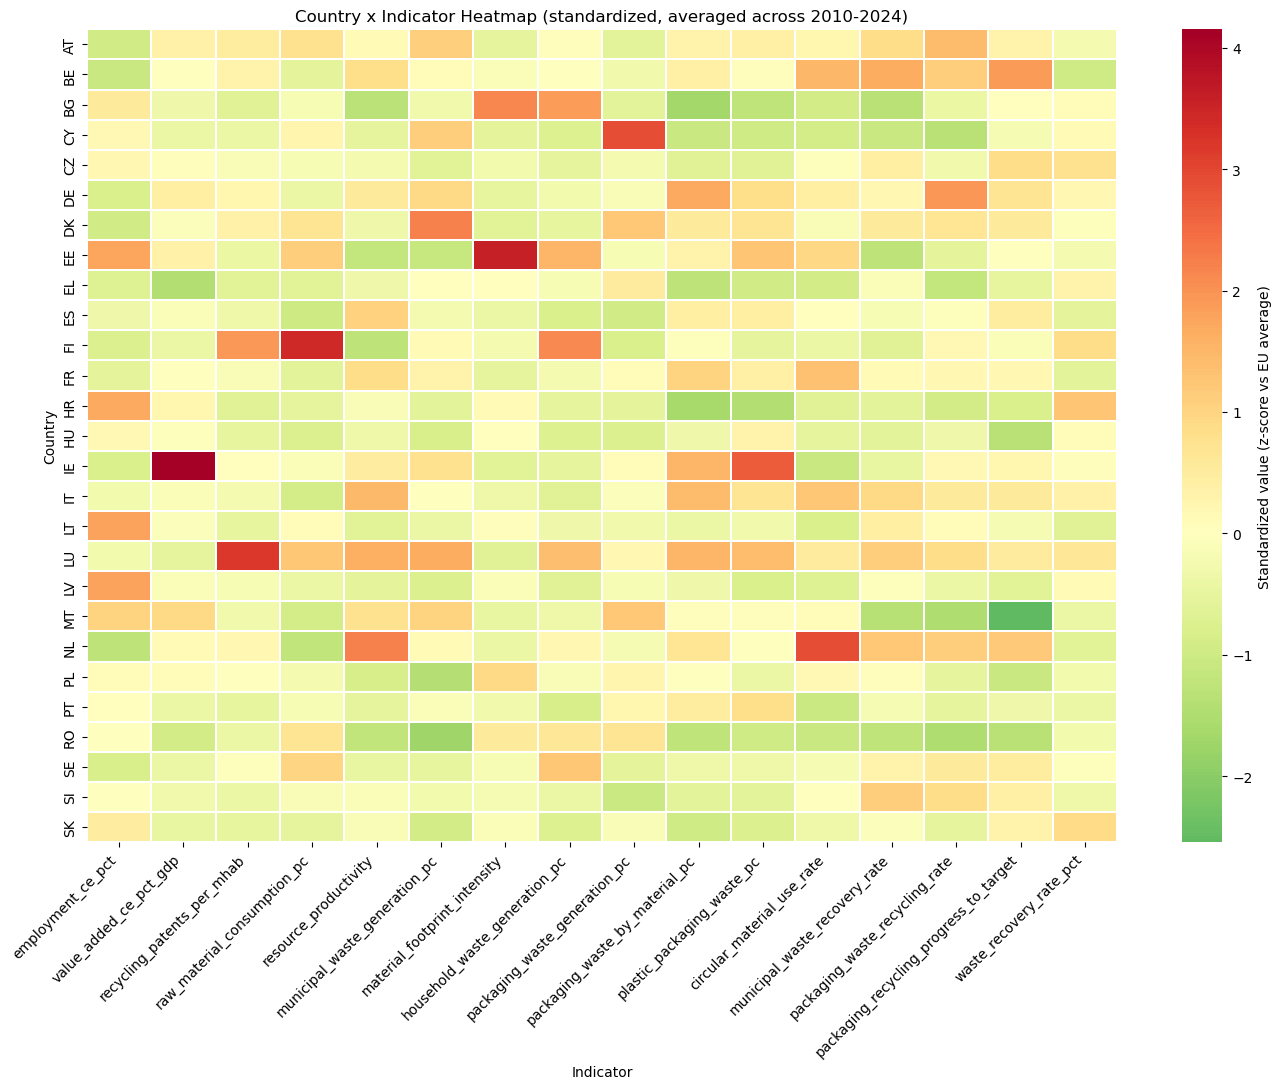

In [115]:
import seaborn as sns
import matplotlib.pyplot as plt

# Build country-level averages (across all years) from the standardized panel data
profile_scaled = pd.DataFrame(X_panel_scaled, columns=FEATURE_COLS_FULL, index=panel_clean.index)
profile_scaled["geo"] = panel_clean["geo"].values

country_indicator_means = profile_scaled.groupby("geo")[FEATURE_COLS_FULL].mean()

plt.figure(figsize=(14, 11))
sns.heatmap(country_indicator_means, cmap="RdYlGn_r", center=0,
            cbar_kws={'label': 'Standardized value (z-score vs EU average)'},
            linewidths=0.3, linecolor='white')
plt.title("Country x Indicator Heatmap (standardized, averaged across 2010-2024)")
plt.xlabel("Indicator")
plt.ylabel("Country")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("outputs/country_indicator_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

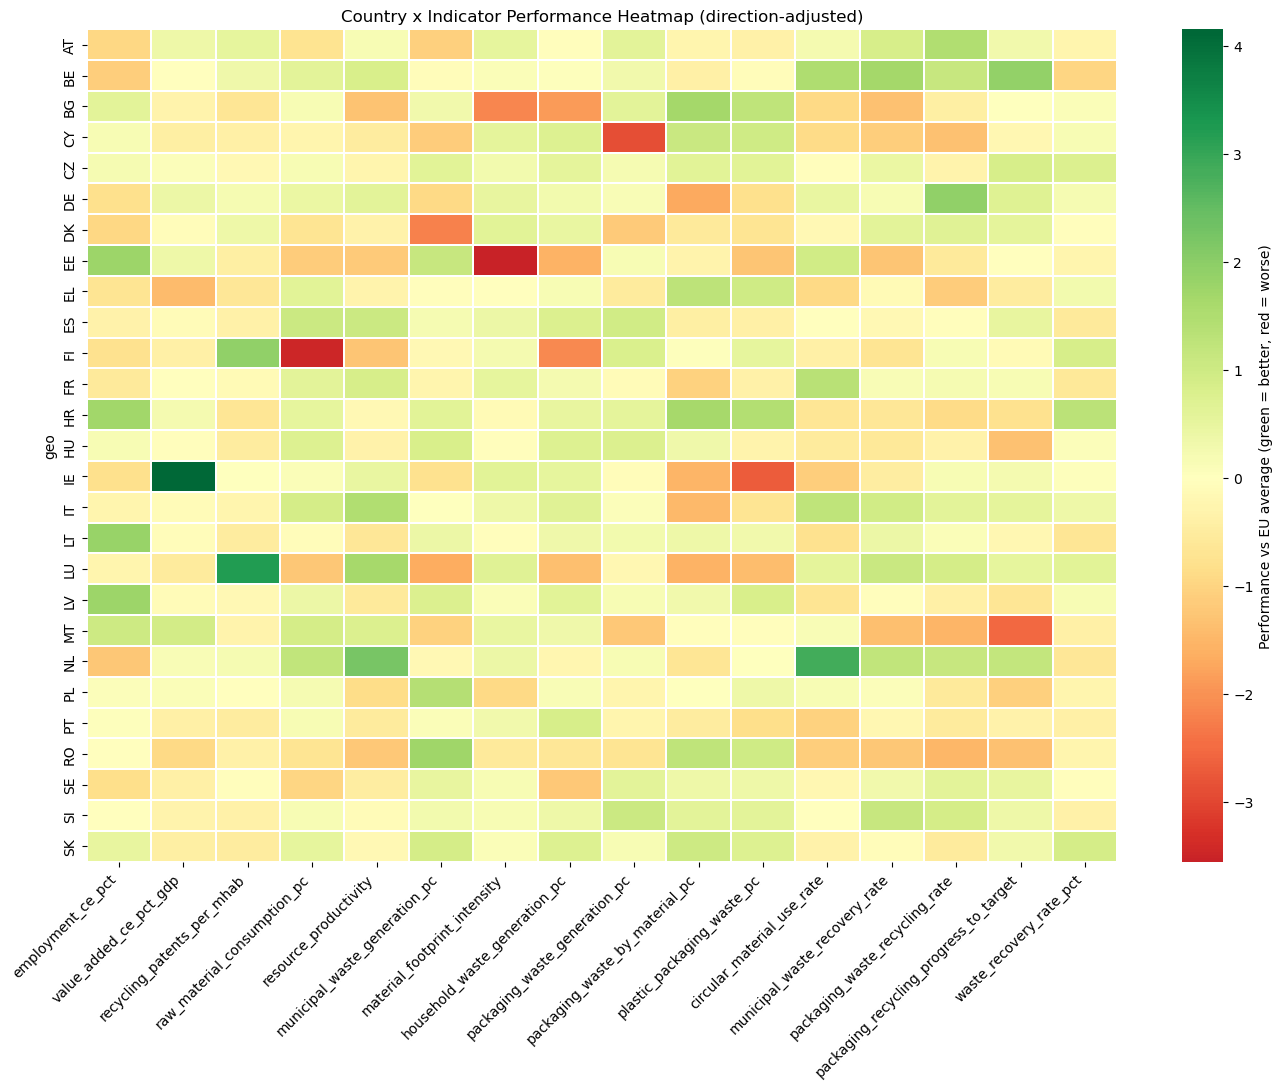

In [116]:
# Indicators where LOWER is better - flip their sign so the heatmap reads consistently
lower_is_better = [
    "raw_material_consumption_pc", "municipal_waste_generation_pc",
    "material_footprint_intensity", "household_waste_generation_pc",
    "packaging_waste_generation_pc", "packaging_waste_by_material_pc",
    "plastic_packaging_waste_pc"
]

country_indicator_performance = country_indicator_means.copy()
for col in lower_is_better:
    country_indicator_performance[col] = -country_indicator_performance[col]

plt.figure(figsize=(14, 11))
sns.heatmap(country_indicator_performance, cmap="RdYlGn", center=0,
            cbar_kws={'label': 'Performance vs EU average (green = better, red = worse)'},
            linewidths=0.3, linecolor='white')
plt.title("Country x Indicator Performance Heatmap (direction-adjusted)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("outputs/country_indicator_performance_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

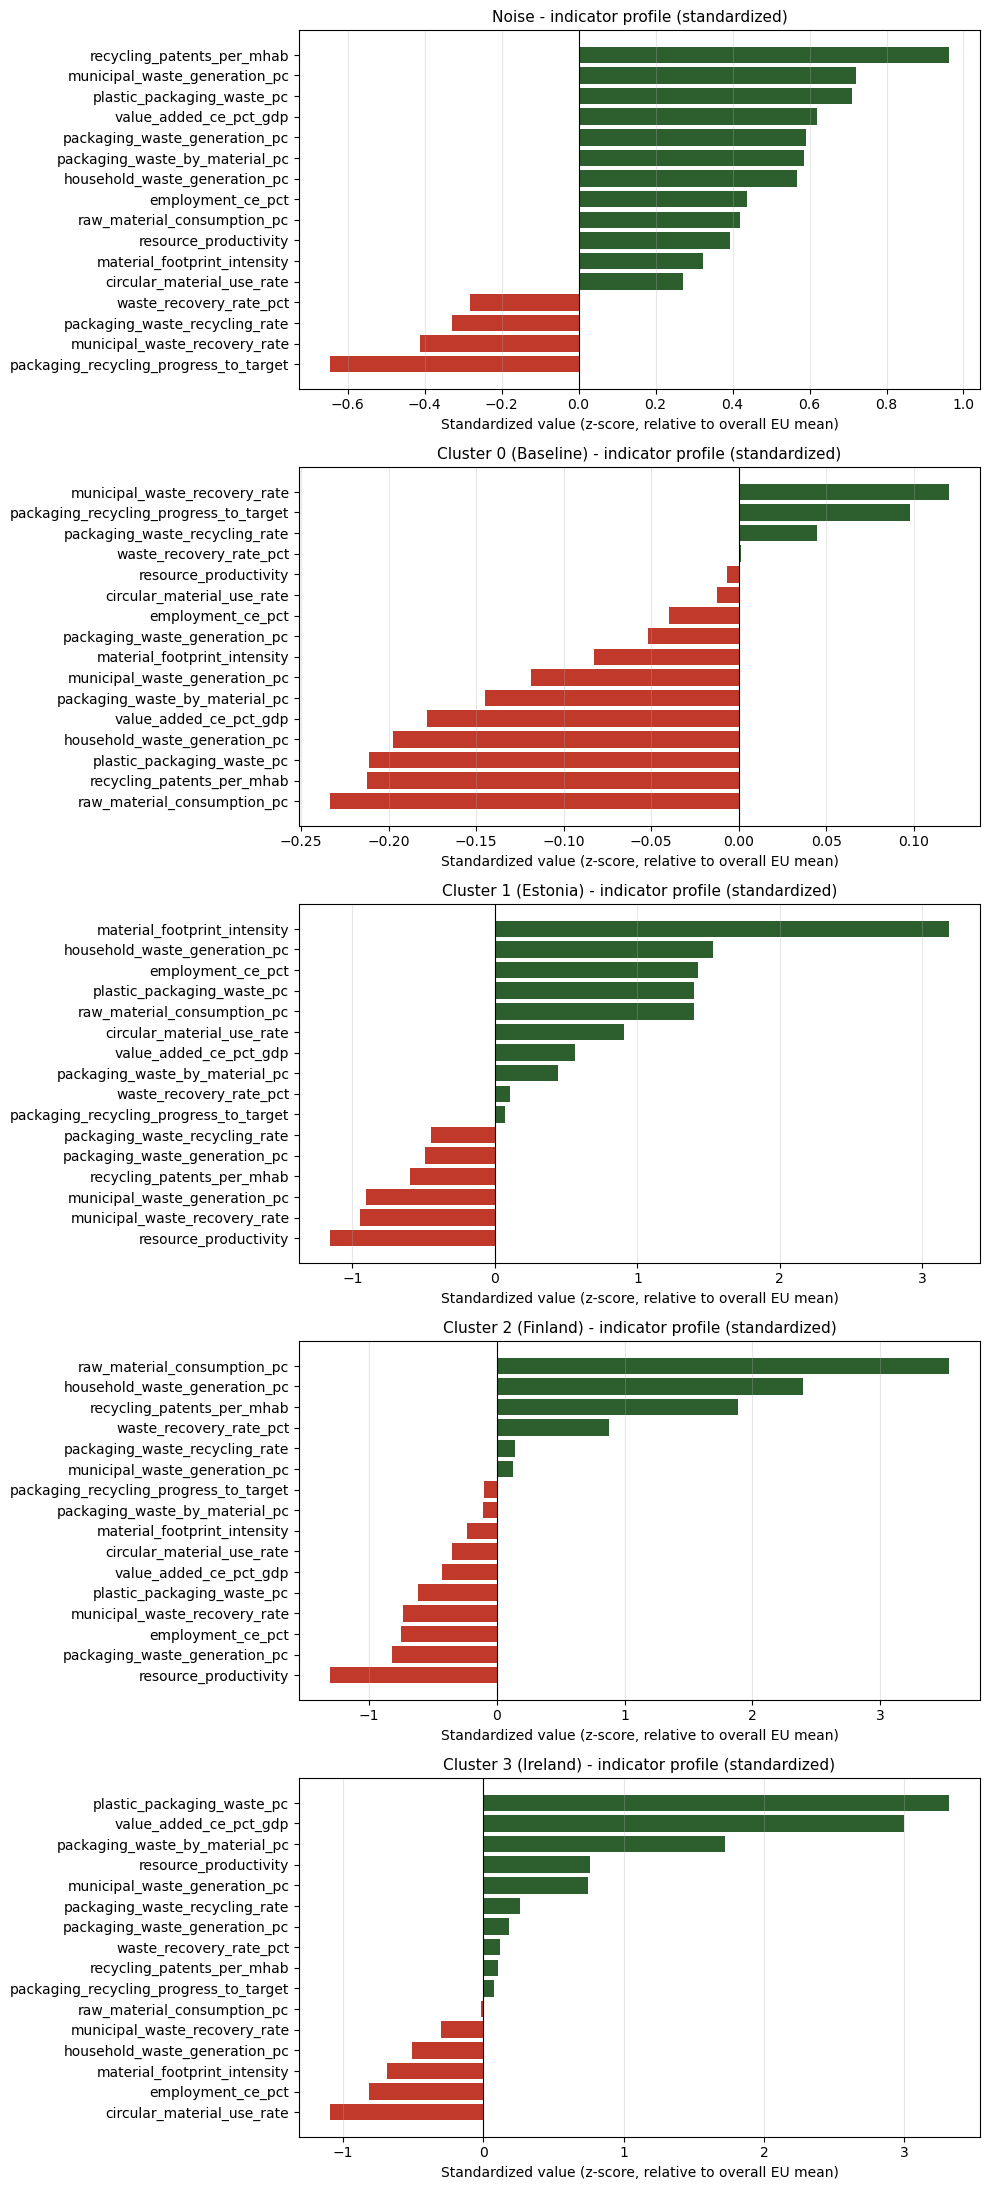

In [117]:
import matplotlib.pyplot as plt

# Rebuild profile_scaled if not already in memory
profile_scaled = pd.DataFrame(X_panel_scaled, columns=FEATURE_COLS_FULL, index=panel_clean.index)
profile_scaled["cluster"] = db_labels_panel

cluster_means_scaled = profile_scaled.groupby("cluster")[FEATURE_COLS_FULL].mean()

# FIXED: Cluster 3 confirmed as Ireland (was previously "(?)")
cluster_labels = {-1: "Noise", 0: "Cluster 0 (Baseline)", 1: "Cluster 1 (Estonia)",
                   2: "Cluster 2 (Finland)", 3: "Cluster 3 (Ireland)"}

fig, axes = plt.subplots(5, 1, figsize=(10, 22))
for ax, cluster_id in zip(axes, [-1, 0, 1, 2, 3]):
    values = cluster_means_scaled.loc[cluster_id].sort_values()
    colors = ['#C0392B' if v < 0 else '#2C5F2D' for v in values]
    ax.barh(values.index, values.values, color=colors)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f"{cluster_labels[cluster_id]} - indicator profile (standardized)", fontsize=11)
    ax.set_xlabel("Standardized value (z-score, relative to overall EU mean)")
    ax.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig("outputs/cluster_bar_profiles.png", dpi=150, bbox_inches="tight")
plt.show()